In [45]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [46]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

print("API token stored for this Colab session.")

Enter your Kaggle API token: ··········
API token stored for this Colab session.


In [47]:
!pip -q install --upgrade kaggle

In [48]:
import os

if not os.environ.get("KAGGLE_API_TOKEN"):
    raise ValueError("Kaggle API token not found. Please set it first.")

print("Kaggle API token is available.")

Kaggle API token is available.


In [49]:
!kaggle datasets download -d pkdarabi/solarpanel -p /content/solar_dataset

Dataset URL: https://www.kaggle.com/datasets/pkdarabi/solarpanel
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
solarpanel.zip: Skipping, found more recently modified local copy (use --force to force download)


In [50]:
import zipfile
from pathlib import Path

download_dir = Path("/content/solar_dataset")
zip_files = list(download_dir.glob("*.zip"))

if not zip_files:
    print("No ZIP file found. Check the download output.")
else:
    with zipfile.ZipFile(zip_files[0], "r") as z:
        z.extractall(download_dir / "extracted")

    print("Dataset extracted successfully!")
    print("Location:", download_dir / "extracted")

Dataset extracted successfully!
Location: /content/solar_dataset/extracted


In [7]:
from pathlib import Path

ROOT = Path("/content/solar_dataset/extracted")

print("Top-level contents:")
for item in ROOT.iterdir():
    print("📁" if item.is_dir() else "📄", item.name)

print("\nSearching for image and label folders:")
for folder in ROOT.rglob("*"):
    if folder.is_dir() and folder.name in ["images", "labels"]:
        print(folder)

Top-level contents:
📁 ImageSet

Searching for image and label folders:
/content/solar_dataset/extracted/ImageSet/train/labels
/content/solar_dataset/extracted/ImageSet/train/images
/content/solar_dataset/extracted/ImageSet/valid/labels
/content/solar_dataset/extracted/ImageSet/valid/images
/content/solar_dataset/extracted/ImageSet/test/labels
/content/solar_dataset/extracted/ImageSet/test/images


In [8]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")

CLASS_NAMES = [
    "MultiByPassed",
    "MultiDiode",
    "MultiHotSpot",
    "SingleByPassed",
    "SingleDiode",
    "SingleHotSpot",
    "StringOpenCircuit",
    "StringReversedPolarity"
]

records = []

for split in ["train", "valid", "test"]:
    label_dir = DATASET_DIR / split / "labels"
    class_counts = Counter()
    boxes_per_image = []

    for label_file in label_dir.glob("*.txt"):
        count = 0

        for line in label_file.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id, xc, yc, bw, bh = map(float, parts)

            if not (class_id.is_integer() and 0 <= int(class_id) < len(CLASS_NAMES)):
                continue

            class_id = int(class_id)
            class_counts[class_id] += 1
            count += 1

            records.append({
                "split": split,
                "class_name": CLASS_NAMES[class_id],
                "width_fraction": bw,
                "height_fraction": bh,
                "area_fraction": bw * bh
            })

        boxes_per_image.append(count)

    print(f"\n{'=' * 40}\n{split.upper()}")
    print("Label files:", len(boxes_per_image))
    print("Total annotated objects:", sum(boxes_per_image))
    print("Average objects per image:",
          round(np.mean(boxes_per_image), 2) if boxes_per_image else 0)

    for i, name in enumerate(CLASS_NAMES):
        print(f"{name}: {class_counts[i]}")

df = pd.DataFrame(records)

print("\nOVERALL CLASS DISTRIBUTION")
print(df["class_name"].value_counts().to_string())

print("\nBOUNDING BOX SIZE STATISTICS")
print(
    df[["width_fraction", "height_fraction", "area_fraction"]]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(4)
)


TRAIN
Label files: 6924
Total annotated objects: 19689
Average objects per image: 2.84
MultiByPassed: 357
MultiDiode: 963
MultiHotSpot: 5021
SingleByPassed: 2957
SingleDiode: 1841
SingleHotSpot: 7251
StringOpenCircuit: 1191
StringReversedPolarity: 108

VALID
Label files: 400
Total annotated objects: 1119
Average objects per image: 2.8
MultiByPassed: 34
MultiDiode: 77
MultiHotSpot: 209
SingleByPassed: 263
SingleDiode: 128
SingleHotSpot: 323
StringOpenCircuit: 69
StringReversedPolarity: 16

TEST
Label files: 15
Total annotated objects: 31
Average objects per image: 2.07
MultiByPassed: 0
MultiDiode: 1
MultiHotSpot: 7
SingleByPassed: 11
SingleDiode: 10
SingleHotSpot: 2
StringOpenCircuit: 0
StringReversedPolarity: 0

OVERALL CLASS DISTRIBUTION
class_name
SingleHotSpot             7576
MultiHotSpot              5237
SingleByPassed            3231
SingleDiode               1979
StringOpenCircuit         1260
MultiDiode                1041
MultiByPassed              391
StringReversedPolarity

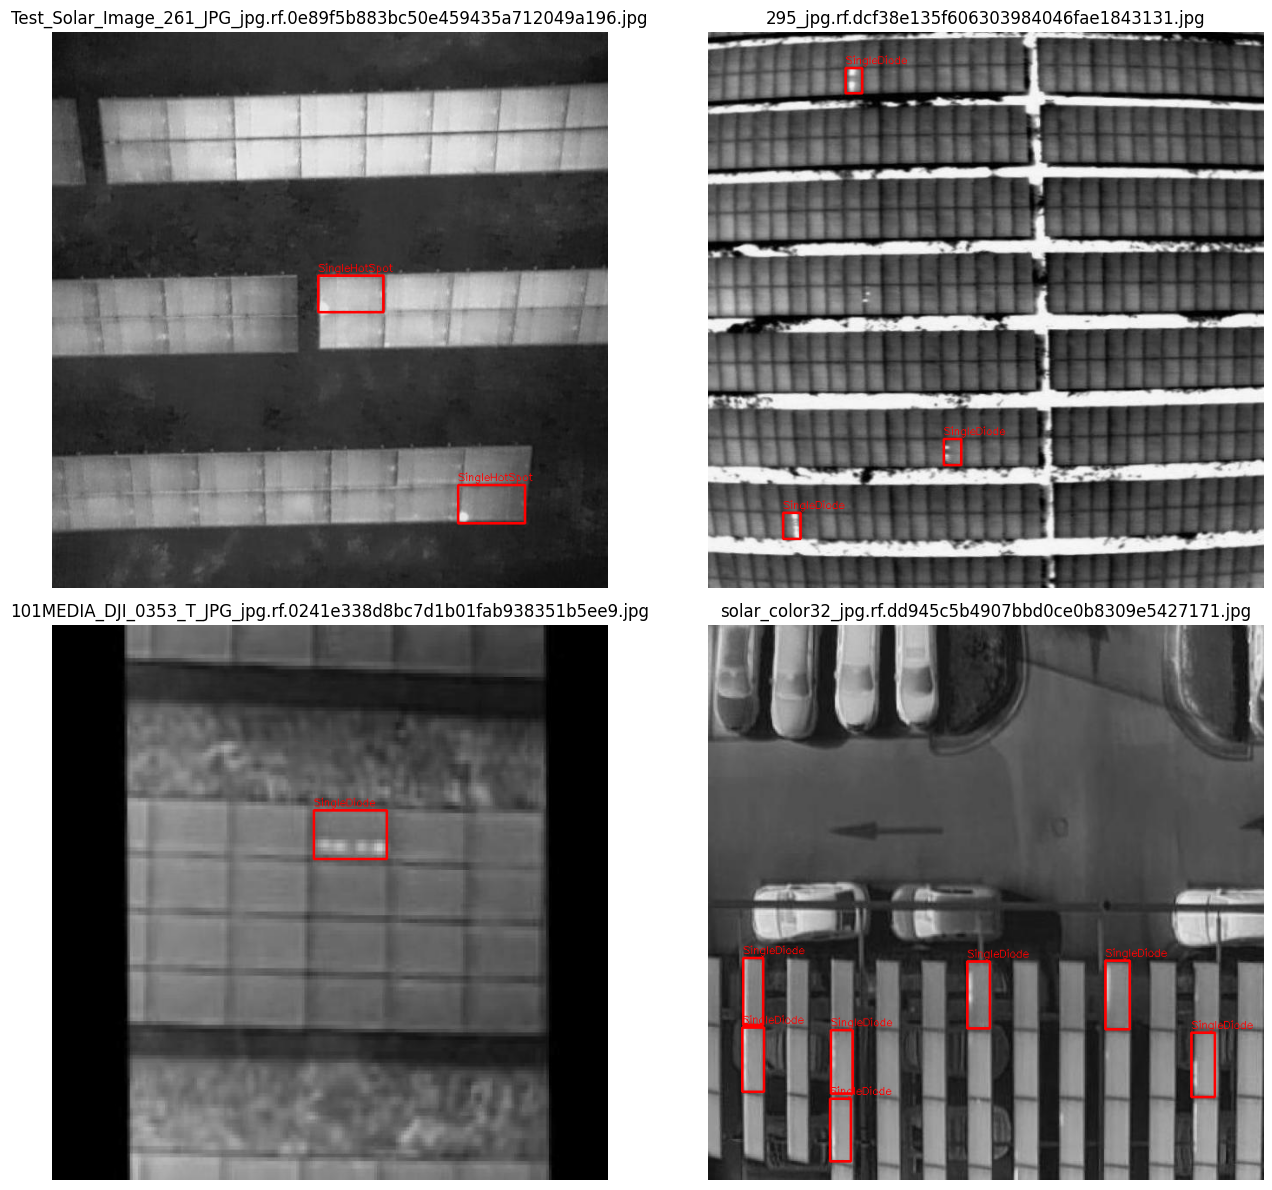

In [9]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

CLASS_NAMES = [
    "MultiByPassed", "MultiDiode", "MultiHotSpot",
    "SingleByPassed", "SingleDiode", "SingleHotSpot",
    "StringOpenCircuit", "StringReversedPolarity"
]

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
)

random.seed(42)
samples = random.sample(image_paths, min(4, len(image_paths)))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, path in zip(axes, samples):
    image = cv2.imread(str(path))

    if image is None:
        ax.set_title(f"Could not load {path.name}")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = LABEL_DIR / f"{path.stem}.txt"

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, parts)
        x1 = int((xc - bw / 2) * width)
        y1 = int((yc - bh / 2) * height)
        x2 = int((xc + bw / 2) * width)
        y2 = int((yc + bh / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        name = CLASS_NAMES[int(class_id)]
        cv2.putText(
            image, name, (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1
        )

    ax.imshow(image, cmap="gray")
    ax.set_title(path.name)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

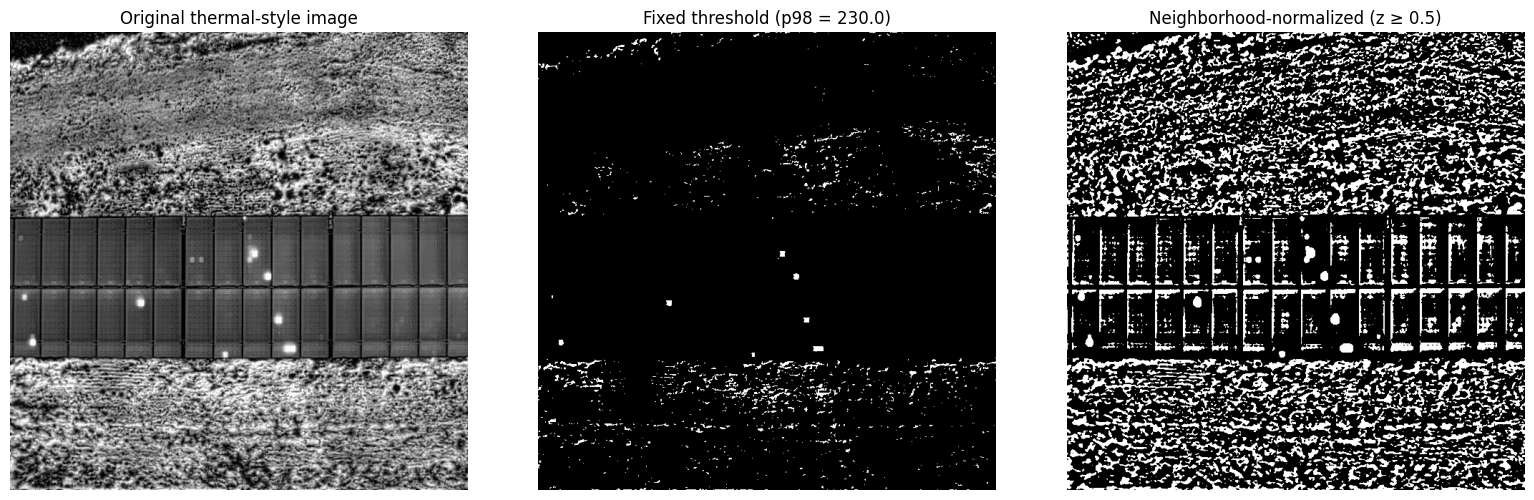

Image: 0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg
Image dimensions: (640, 640)
Fixed threshold: 230.0
Fixed mask coverage: 2.02%
Normalized mask coverage: 26.77%


In [10]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

# Select the first validation image with a non-empty label file
image_path = next(
    p for p in sorted(IMAGE_DIR.iterdir())
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)

gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if gray is None:
    raise ValueError(f"Could not read {image_path}")

# Method 1: Fixed-intensity threshold
fixed_threshold = np.percentile(gray, 98)
fixed_mask = (gray >= fixed_threshold).astype(np.uint8) * 255

# Method 2: Neighborhood-normalized threshold
smooth = cv2.GaussianBlur(gray.astype(np.float32), (3, 3), 0)

local_mean = cv2.GaussianBlur(
    smooth, (0, 0), sigmaX=9, sigmaY=9
)
local_sq_mean = cv2.GaussianBlur(
    smooth**2, (0, 0), sigmaX=9, sigmaY=9
)

local_std = np.sqrt(
    np.maximum(local_sq_mean - local_mean**2, 0)
)

z_score = (smooth - local_mean) / (local_std + 2.0)
normalized_mask = (z_score >= 0.5).astype(np.uint8) * 255

# Display image and masks
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original thermal-style image")

axes[1].imshow(fixed_mask, cmap="gray")
axes[1].set_title(f"Fixed threshold (p98 = {fixed_threshold:.1f})")

axes[2].imshow(normalized_mask, cmap="gray")
axes[2].set_title("Neighborhood-normalized (z ≥ 0.5)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path.name)
print("Image dimensions:", gray.shape)
print(f"Fixed threshold: {fixed_threshold:.1f}")
print(f"Fixed mask coverage: {np.mean(fixed_mask > 0) * 100:.2f}%")
print(f"Normalized mask coverage: {np.mean(normalized_mask > 0) * 100:.2f}%")


Fixed threshold
Pixel precision: 0.0501
Pixel recall:    0.0189
Pixel F1-score:  0.0275

Neighborhood-normalized
Pixel precision: 0.0343
Pixel recall:    0.1720
Pixel F1-score:  0.0572


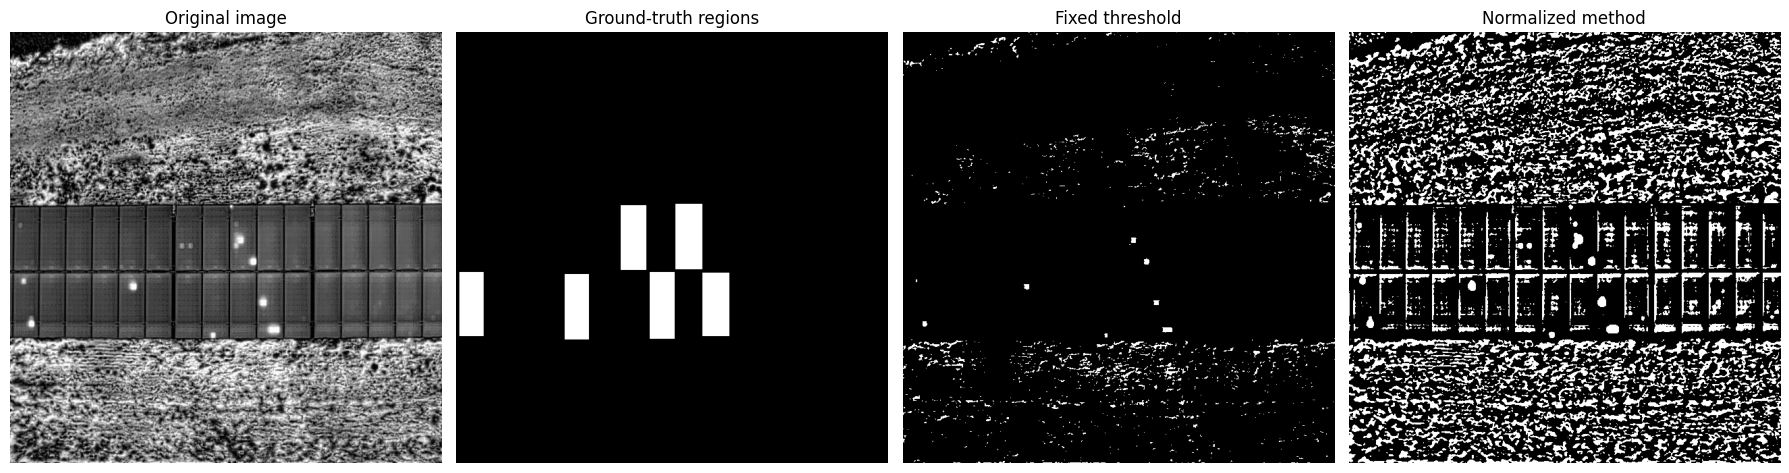

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

label_path = LABEL_DIR / f"{image_path.stem}.txt"
height, width = gray.shape

# Create ground-truth binary mask from YOLO boxes
gt_mask = np.zeros((height, width), dtype=np.uint8)

for line in label_path.read_text().splitlines():
    parts = line.split()
    if len(parts) != 5:
        continue

    class_id, xc, yc, bw, bh = map(float, parts)

    x1 = max(0, int((xc - bw / 2) * width))
    y1 = max(0, int((yc - bh / 2) * height))
    x2 = min(width, int((xc + bw / 2) * width))
    y2 = min(height, int((yc + bh / 2) * height))

    gt_mask[y1:y2, x1:x2] = 255

def calculate_metrics(pred_mask, gt_mask):
    pred = pred_mask > 0
    gt = gt_mask > 0

    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1

for name, mask in [
    ("Fixed threshold", fixed_mask),
    ("Neighborhood-normalized", normalized_mask)
]:
    precision, recall, f1 = calculate_metrics(mask, gt_mask)

    print(f"\n{name}")
    print(f"Pixel precision: {precision:.4f}")
    print(f"Pixel recall:    {recall:.4f}")
    print(f"Pixel F1-score:  {f1:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

items = [
    (gray, "Original image", "gray"),
    (gt_mask, "Ground-truth regions", "gray"),
    (fixed_mask, "Fixed threshold", "gray"),
    (normalized_mask, "Normalized method", "gray")
]

for ax, (image, title, cmap) in zip(axes, items):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)[:50]

Z_THRESHOLDS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
results = []

for threshold in Z_THRESHOLDS:
    total_tp = total_fp = total_fn = 0

    for path in image_paths:
        gray_img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if gray_img is None:
            continue

        h, w = gray_img.shape
        gt = np.zeros((h, w), dtype=bool)

        for line in (LABEL_DIR / f"{path.stem}.txt").read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            _, xc, yc, bw, bh = map(float, parts)
            x1 = max(0, int((xc - bw / 2) * w))
            y1 = max(0, int((yc - bh / 2) * h))
            x2 = min(w, int((xc + bw / 2) * w))
            y2 = min(h, int((yc + bh / 2) * h))
            gt[y1:y2, x1:x2] = True

        smooth = cv2.GaussianBlur(
            gray_img.astype(np.float32), (3, 3), 0
        )
        local_mean = cv2.GaussianBlur(
            smooth, (0, 0), sigmaX=9, sigmaY=9
        )
        local_sq_mean = cv2.GaussianBlur(
            smooth**2, (0, 0), sigmaX=9, sigmaY=9
        )
        local_std = np.sqrt(
            np.maximum(local_sq_mean - local_mean**2, 0)
        )

        z_score = (smooth - local_mean) / (local_std + 2.0)
        pred = z_score >= threshold

        total_tp += np.count_nonzero(pred & gt)
        total_fp += np.count_nonzero(pred & ~gt)
        total_fn += np.count_nonzero(~pred & gt)

    precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
    recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "z_threshold": threshold,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "flagged_pixel_percentage": (
            100 * (total_tp + total_fp) /
            (len(image_paths) * 640 * 640)
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

 z_threshold  precision  recall     F1  flagged_pixel_percentage
         0.5     0.0212  0.2630 0.0392                   22.9376
         1.0     0.0252  0.0597 0.0354                    4.3891
         1.5     0.0392  0.0172 0.0239                    0.8123
         2.0     0.0784  0.0057 0.0106                    0.1334
         2.5     0.1310  0.0015 0.0031                    0.0218
         3.0     0.2071  0.0004 0.0008                    0.0034


Annotated boxes analysed: 113

Intensity statistics:
       box_mean  surrounding_mean  intensity_difference
count    113.00            113.00                113.00
mean     121.84             95.70                 26.13
std       36.80             34.55                 16.52
min       56.72             42.44                 -8.50
25%       95.53             72.63                 14.32
50%      116.26             85.97                 24.86
75%      145.18            108.29                 37.18
max      214.87            205.12                 72.70

Fraction of boxes brighter than their surroundings: 0.973


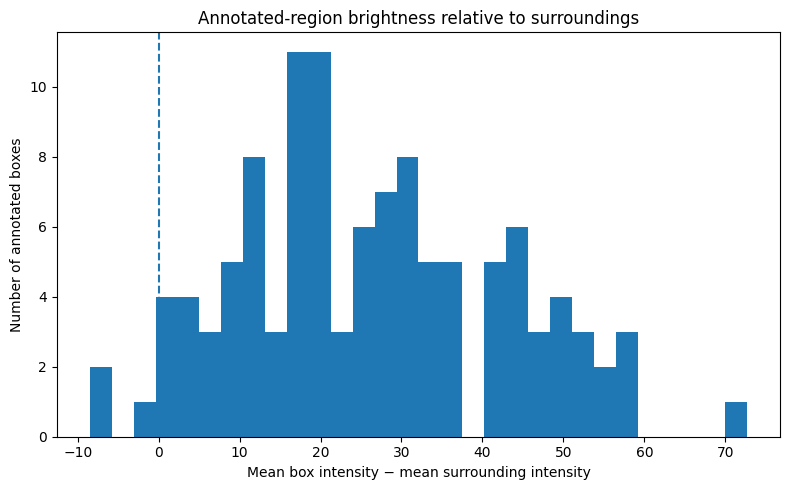

In [13]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

# Reuse the same first 50 validation images
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)[:50]

records = []

for path in image_paths:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        continue

    h, w = gray.shape

    for line in (LABEL_DIR / f"{path.stem}.txt").read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, parts)

        x1 = max(0, int((xc - bw / 2) * w))
        y1 = max(0, int((yc - bh / 2) * h))
        x2 = min(w, int((xc + bw / 2) * w))
        y2 = min(h, int((yc + bh / 2) * h))

        if x2 <= x1 or y2 <= y1:
            continue

        # Pixels inside the annotated rectangle
        roi = gray[y1:y2, x1:x2]

        # Surrounding ring, excluding the annotation rectangle
        pad = 10
        sx1, sy1 = max(0, x1-pad), max(0, y1-pad)
        sx2, sy2 = min(w, x2+pad), min(h, y2+pad)

        surrounding = gray[sy1:sy2, sx1:sx2].copy()
        surrounding[y1-sy1:y2-sy1, x1-sx1:x2-sx1] = 0

        ring_mask = np.ones(surrounding.shape, dtype=bool)
        ring_mask[y1-sy1:y2-sy1, x1-sx1:x2-sx1] = False
        ring_pixels = surrounding[ring_mask]

        if roi.size == 0 or ring_pixels.size == 0:
            continue

        records.append({
            "image": path.name,
            "class_id": int(class_id),
            "box_mean": float(np.mean(roi)),
            "box_median": float(np.median(roi)),
            "surrounding_mean": float(np.mean(ring_pixels)),
            "intensity_difference": float(
                np.mean(roi) - np.mean(ring_pixels)
            )
        })

intensity_df = pd.DataFrame(records)

print("Annotated boxes analysed:", len(intensity_df))
print("\nIntensity statistics:")
print(
    intensity_df[
        ["box_mean", "surrounding_mean", "intensity_difference"]
    ].describe().round(2)
)

print("\nFraction of boxes brighter than their surroundings:",
      round((intensity_df["intensity_difference"] > 0).mean(), 3))

plt.figure(figsize=(8, 5))
plt.hist(intensity_df["intensity_difference"], bins=30)
plt.axvline(0, linestyle="--")
plt.xlabel("Mean box intensity − mean surrounding intensity")
plt.ylabel("Number of annotated boxes")
plt.title("Annotated-region brightness relative to surroundings")
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)[:50]

DIFF_THRESHOLDS = [5, 10, 15, 20, 25, 30, 40]
results = []

for threshold in DIFF_THRESHOLDS:
    tp = fp = fn = flagged = total_pixels = 0

    for path in image_paths:
        gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            continue

        h, w = gray.shape
        gt = np.zeros((h, w), dtype=bool)

        for line in (LABEL_DIR / f"{path.stem}.txt").read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            _, xc, yc, bw, bh = map(float, parts)
            x1 = max(0, int((xc - bw / 2) * w))
            y1 = max(0, int((yc - bh / 2) * h))
            x2 = min(w, int((xc + bw / 2) * w))
            y2 = min(h, int((yc + bh / 2) * h))

            if x2 > x1 and y2 > y1:
                gt[y1:y2, x1:x2] = True

        smooth = cv2.GaussianBlur(
            gray.astype(np.float32), (3, 3), 0
        )

        local_mean = cv2.GaussianBlur(
            smooth, (0, 0), sigmaX=9, sigmaY=9
        )

        local_difference = smooth - local_mean
        pred = local_difference >= threshold

        tp += np.count_nonzero(pred & gt)
        fp += np.count_nonzero(pred & ~gt)
        fn += np.count_nonzero(~pred & gt)
        flagged += np.count_nonzero(pred)
        total_pixels += pred.size

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "difference_threshold": threshold,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "flagged_pixel_percentage": 100 * flagged / total_pixels
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

 difference_threshold  precision  recall     F1  flagged_pixel_percentage
                    5     0.0225  0.4118 0.0426                   33.9217
                   10     0.0235  0.2837 0.0435                   22.2967
                   15     0.0247  0.2017 0.0441                   15.0774
                   20     0.0264  0.1469 0.0448                   10.2923
                   25     0.0275  0.1064 0.0437                    7.1495
                   30     0.0271  0.0756 0.0399                    5.1596
                   40     0.0266  0.0412 0.0323                    2.8653


In [15]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

# Dataset paths
DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"

# Select 50 validation images containing annotations
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)[:50]

print("Validation images selected:", len(image_paths))

# Convert YOLO annotations to pixel-coordinate bounding boxes
def load_ground_truth(label_path, width, height):
    boxes = []

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, bw, bh = map(float, parts)

        x1 = max(0, int((xc - bw / 2) * width))
        y1 = max(0, int((yc - bh / 2) * height))
        x2 = min(width, int((xc + bw / 2) * width))
        y2 = min(height, int((yc + bh / 2) * height))

        if x2 > x1 and y2 > y1:
            boxes.append([x1, y1, x2, y2])

    return boxes


# Generate predicted boxes from a binary mask
def get_predicted_boxes(mask, min_area=20):
    binary = mask.astype(np.uint8)

    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )

    boxes = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area >= min_area:
            boxes.append([x, y, x + w, y + h])

    return boxes


# Intersection over Union
def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (
        (box_a[2] - box_a[0]) *
        (box_a[3] - box_a[1])
    )

    area_b = (
        (box_b[2] - box_b[0]) *
        (box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


# One-to-one matching: each ground-truth box can match once
def evaluate_boxes(pred_boxes, gt_boxes, iou_threshold=0.5):
    candidates = []

    for pi, pred in enumerate(pred_boxes):
        for gi, gt in enumerate(gt_boxes):
            iou = calculate_iou(pred, gt)

            if iou >= iou_threshold:
                candidates.append((iou, pi, gi))

    # Highest-IoU matches are considered first
    candidates.sort(reverse=True)

    matched_predictions = set()
    matched_ground_truth = set()

    for iou, pi, gi in candidates:
        if pi not in matched_predictions and gi not in matched_ground_truth:
            matched_predictions.add(pi)
            matched_ground_truth.add(gi)

    tp = len(matched_predictions)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - len(matched_ground_truth)

    return tp, fp, fn


# Evaluate both methods
methods = {
    "Fixed threshold": [],
    "Local intensity difference": []
}

for path in image_paths:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        continue

    h, w = gray.shape

    gt_boxes = load_ground_truth(
        LABEL_DIR / f"{path.stem}.txt", w, h
    )

    # Smooth image to reduce isolated pixel noise
    smooth = cv2.GaussianBlur(
        gray.astype(np.float32), (3, 3), 0
    )

    # Method 1: global intensity threshold
    fixed_threshold = np.percentile(smooth, 98)
    fixed_mask = smooth >= fixed_threshold

    # Method 2: difference from local neighbourhood mean
    local_mean = cv2.GaussianBlur(
        smooth, (0, 0), sigmaX=9, sigmaY=9
    )

    local_difference = smooth - local_mean
    local_mask = local_difference >= 20

    # Remove tiny components and obtain predicted boxes
    fixed_boxes = get_predicted_boxes(fixed_mask, min_area=20)
    local_boxes = get_predicted_boxes(local_mask, min_area=20)

    # Evaluate each method
    for name, predictions in [
        ("Fixed threshold", fixed_boxes),
        ("Local intensity difference", local_boxes)
    ]:
        tp, fp, fn = evaluate_boxes(
            predictions, gt_boxes, iou_threshold=0.5
        )

        methods[name].append({
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Predicted boxes": len(predictions),
            "Ground-truth boxes": len(gt_boxes)
        })


# Summarize results across all images
summary = []

for name, rows in methods.items():
    df = pd.DataFrame(rows)

    tp = int(df["TP"].sum())
    fp = int(df["FP"].sum())
    fn = int(df["FN"].sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    summary.append({
        "Method": name,
        "Images evaluated": len(df),
        "Ground-truth boxes": int(df["Ground-truth boxes"].sum()),
        "Predicted boxes": int(df["Predicted boxes"].sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

results_df = pd.DataFrame(summary)

print("\nOBJECT-LEVEL DETECTION RESULTS (IoU >= 0.5)")
print(results_df.round(4).to_string(index=False))

Validation images selected: 50

OBJECT-LEVEL DETECTION RESULTS (IoU >= 0.5)
                    Method  Images evaluated  Ground-truth boxes  Predicted boxes  TP    FP  FN  Precision  Recall     F1
           Fixed threshold                50                 113             2736  10  2726 103     0.0037  0.0885 0.0070
Local intensity difference                50                 113            14268  10 14258 103     0.0007  0.0885 0.0014


In [16]:
MIN_AREAS = [20, 50, 100, 200, 500]

area_results = []

for min_area in MIN_AREAS:
    for method_name in [
        "Fixed threshold",
        "Local intensity difference"
    ]:
        total_tp = 0
        total_fp = 0
        total_fn = 0
        total_predictions = 0
        total_gt = 0

        for path in image_paths:
            gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

            if gray is None:
                continue

            h, w = gray.shape

            gt_boxes = load_ground_truth(
                LABEL_DIR / f"{path.stem}.txt", w, h
            )

            smooth = cv2.GaussianBlur(
                gray.astype(np.float32), (3, 3), 0
            )

            if method_name == "Fixed threshold":
                threshold = np.percentile(smooth, 98)
                mask = smooth >= threshold

            else:
                local_mean = cv2.GaussianBlur(
                    smooth, (0, 0), sigmaX=9, sigmaY=9
                )
                mask = (smooth - local_mean) >= 20

            pred_boxes = get_predicted_boxes(
                mask, min_area=min_area
            )

            tp, fp, fn = evaluate_boxes(
                pred_boxes, gt_boxes, iou_threshold=0.5
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_predictions += len(pred_boxes)
            total_gt += len(gt_boxes)

        precision = (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp else 0
        )

        recall = (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        area_results.append({
            "Method": method_name,
            "Min_component_area": min_area,
            "Predicted_boxes": total_predictions,
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

area_results_df = pd.DataFrame(area_results)

print("RESULTS BY MINIMUM COMPONENT AREA")
print(area_results_df.round(4).to_string(index=False))

RESULTS BY MINIMUM COMPONENT AREA
                    Method  Min_component_area  Predicted_boxes  TP    FP  FN  Precision  Recall     F1
           Fixed threshold                  20             2736  10  2726 103     0.0037  0.0885 0.0070
Local intensity difference                  20            14268  10 14258 103     0.0007  0.0885 0.0014
           Fixed threshold                  50             1251  10  1241 103     0.0080  0.0885 0.0147
Local intensity difference                  50             8750  10  8740 103     0.0011  0.0885 0.0023
           Fixed threshold                 100              672  10   662 103     0.0149  0.0885 0.0255
Local intensity difference                 100             5316  10  5306 103     0.0019  0.0885 0.0037
           Fixed threshold                 200              364  10   354 103     0.0275  0.0885 0.0419
Local intensity difference                 200             2378  10  2368 103     0.0042  0.0885 0.0080
           Fixed threshold    

In [17]:
import cv2
import numpy as np
import pandas as pd

geometry_results = []

for path in image_paths:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        continue

    h, w = gray.shape

    # Ground-truth box areas
    gt_boxes = load_ground_truth(
        LABEL_DIR / f"{path.stem}.txt", w, h
    )

    for x1, y1, x2, y2 in gt_boxes:
        geometry_results.append({
            "Type": "Ground truth",
            "Area": (x2 - x1) * (y2 - y1),
            "Width": x2 - x1,
            "Height": y2 - y1
        })

    # Prepare threshold masks
    smooth = cv2.GaussianBlur(
        gray.astype(np.float32), (3, 3), 0
    )

    fixed_threshold = np.percentile(smooth, 98)
    fixed_mask = (smooth >= fixed_threshold).astype(np.uint8)

    local_mean = cv2.GaussianBlur(
        smooth, (0, 0), sigmaX=9, sigmaY=9
    )
    local_mask = (
        (smooth - local_mean) >= 20
    ).astype(np.uint8)

    for method_name, mask in [
        ("Fixed threshold", fixed_mask),
        ("Local intensity difference", local_mask)
    ]:
        count, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(
                mask, connectivity=8
            )
        )

        for i in range(1, count):
            x, y, cw, ch, area = stats[i]

            if area >= 200:
                geometry_results.append({
                    "Type": method_name,
                    "Area": int(area),
                    "Width": int(cw),
                    "Height": int(ch)
                })

geometry_df = pd.DataFrame(geometry_results)

print("BOX AND COMPONENT GEOMETRY")
print(
    geometry_df.groupby("Type")[
        ["Area", "Width", "Height"]
    ].agg(["count", "median", "mean", "max"]).round(2)
)

BOX AND COMPONENT GEOMETRY
                            Area                         Width                \
                           count  median     mean    max count median   mean   
Type                                                                           
Fixed threshold              364   420.5   638.08   5563   364   25.5  36.71   
Ground truth                 113  2580.0  3353.94  29160   113   38.0  60.65   
Local intensity difference  2378   296.0   488.91   7291  2378   31.5  47.11   

                                Height                     
                            max  count median   mean  max  
Type                                                       
Fixed threshold             249    364   27.0  32.87  153  
Ground truth                486    113   45.0  58.27  172  
Local intensity difference  640   2378   23.0  29.75  640  


In [18]:
import cv2
import numpy as np
import pandas as pd

KERNEL_SIZES = [3, 7, 11]
morph_results = []

for method_name in [
    "Fixed threshold",
    "Local intensity difference"
]:
    for kernel_size in KERNEL_SIZES:

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (kernel_size, kernel_size)
        )

        total_tp = 0
        total_fp = 0
        total_fn = 0
        total_predictions = 0
        total_gt = 0

        for path in image_paths:
            gray = cv2.imread(
                str(path), cv2.IMREAD_GRAYSCALE
            )

            if gray is None:
                continue

            h, w = gray.shape

            gt_boxes = load_ground_truth(
                LABEL_DIR / f"{path.stem}.txt", w, h
            )

            smooth = cv2.GaussianBlur(
                gray.astype(np.float32), (3, 3), 0
            )

            if method_name == "Fixed threshold":
                threshold = np.percentile(smooth, 98)
                mask = (smooth >= threshold).astype(np.uint8)

            else:
                local_mean = cv2.GaussianBlur(
                    smooth, (0, 0), sigmaX=9, sigmaY=9
                )

                mask = (
                    (smooth - local_mean) >= 20
                ).astype(np.uint8)

            # Close gaps between nearby regions
            closed_mask = cv2.morphologyEx(
                mask,
                cv2.MORPH_CLOSE,
                kernel
            )

            pred_boxes = get_predicted_boxes(
                closed_mask, min_area=200
            )

            tp, fp, fn = evaluate_boxes(
                pred_boxes,
                gt_boxes,
                iou_threshold=0.5
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_predictions += len(pred_boxes)
            total_gt += len(gt_boxes)

        precision = (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp else 0
        )

        recall = (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        morph_results.append({
            "Method": method_name,
            "Kernel_size": kernel_size,
            "Predicted_boxes": total_predictions,
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

morph_df = pd.DataFrame(morph_results)

print("RESULTS WITH MORPHOLOGICAL CLOSING")
print(morph_df.round(4).to_string(index=False))

RESULTS WITH MORPHOLOGICAL CLOSING
                    Method  Kernel_size  Predicted_boxes  TP   FP  FN  Precision  Recall     F1
           Fixed threshold            3              358  12  346 101     0.0335  0.1062 0.0510
           Fixed threshold            7              447  16  431  97     0.0358  0.1416 0.0571
           Fixed threshold           11              469  17  452  96     0.0362  0.1504 0.0584
Local intensity difference            3             2370  12 2358 101     0.0051  0.1062 0.0097
Local intensity difference            7             1545  11 1534 102     0.0071  0.0973 0.0133
Local intensity difference           11             1220  14 1206  99     0.0115  0.1239 0.0210


In [19]:
import cv2
import numpy as np
import pandas as pd

BLOCK_SIZES = [21, 41, 61]
C_VALUES = [2, 5, 10]

adaptive_results = []

# Evaluate adaptive thresholding
for block_size in BLOCK_SIZES:
    for c_value in C_VALUES:

        total_tp = 0
        total_fp = 0
        total_fn = 0
        total_predictions = 0
        total_gt = 0

        for path in image_paths:
            gray = cv2.imread(
                str(path), cv2.IMREAD_GRAYSCALE
            )

            if gray is None:
                continue

            h, w = gray.shape

            gt_boxes = load_ground_truth(
                LABEL_DIR / f"{path.stem}.txt", w, h
            )

            # Adaptive Gaussian threshold
            mask = cv2.adaptiveThreshold(
                gray,
                255,
                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                cv2.THRESH_BINARY,
                block_size,
                c_value
            )

            mask = (mask > 0).astype(np.uint8)

            # Connect nearby regions
            kernel = cv2.getStructuringElement(
                cv2.MORPH_ELLIPSE, (7, 7)
            )

            mask = cv2.morphologyEx(
                mask, cv2.MORPH_CLOSE, kernel
            )

            pred_boxes = get_predicted_boxes(
                mask, min_area=500
            )

            tp, fp, fn = evaluate_boxes(
                pred_boxes,
                gt_boxes,
                iou_threshold=0.5
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_predictions += len(pred_boxes)
            total_gt += len(gt_boxes)

        precision = (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp else 0
        )

        recall = (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        adaptive_results.append({
            "Block_size": block_size,
            "C": c_value,
            "Predicted_boxes": total_predictions,
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

adaptive_df = pd.DataFrame(adaptive_results)

print("ADAPTIVE THRESHOLDING RESULTS")
print(adaptive_df.round(4).to_string(index=False))

ADAPTIVE THRESHOLDING RESULTS
 Block_size  C  Predicted_boxes  TP  FP  FN  Precision  Recall  F1
         21  2               69   0  69 113        0.0     0.0   0
         21  5               53   0  53 113        0.0     0.0   0
         21 10               51   0  51 113        0.0     0.0   0
         41  2              135   0 135 113        0.0     0.0   0
         41  5              102   0 102 113        0.0     0.0   0
         41 10               80   0  80 113        0.0     0.0   0
         61  2              219   0 219 113        0.0     0.0   0
         61  5              137   0 137 113        0.0     0.0   0
         61 10               96   0  96 113        0.0     0.0   0


In [20]:
import cv2
import numpy as np
import pandas as pd

# Select the first available validation image
path = image_paths[0]

gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
h, w = gray.shape

gt_boxes = load_ground_truth(
    LABEL_DIR / f"{path.stem}.txt", w, h
)

# Use the best-performing fixed-threshold configuration so far
smooth = cv2.GaussianBlur(
    gray.astype(np.float32), (3, 3), 0
)

threshold = np.percentile(smooth, 98)
mask = (smooth >= threshold).astype(np.uint8)

pred_boxes = get_predicted_boxes(
    mask, min_area=500
)

print("Image:", path.name)
print("Image dimensions:", w, "x", h)
print("Ground-truth boxes:", len(gt_boxes))
print("Predicted boxes:", len(pred_boxes))

rows = []

for i, gt in enumerate(gt_boxes):
    overlaps = [
        calculate_iou(gt, pred)
        for pred in pred_boxes
    ]

    best_idx = int(np.argmax(overlaps)) if overlaps else -1
    best_iou = overlaps[best_idx] if overlaps else 0.0

    rows.append({
        "GT_box": i + 1,
        "GT_coordinates": gt,
        "Best_predicted_box": (
            pred_boxes[best_idx] if best_idx >= 0 else None
        ),
        "Best_IoU": best_iou
    })

inspection_df = pd.DataFrame(rows)

print("\nBEST PREDICTED BOX FOR EACH GROUND-TRUTH BOX")
print(inspection_df.round(4).to_string(index=False))

print("\nBest-IoU summary:")
if rows:
    ious = inspection_df["Best_IoU"]

    print("Maximum:", round(float(ious.max()), 4))
    print("Median:", round(float(ious.median()), 4))
    print("Boxes with IoU >= 0.5:", int((ious >= 0.5).sum()))
    print("Boxes with IoU >= 0.3:", int((ious >= 0.3).sum()))

Image: 0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg
Image dimensions: 640 x 640
Ground-truth boxes: 6
Predicted boxes: 0

BEST PREDICTED BOX FOR EACH GROUND-TRUTH BOX
 GT_box       GT_coordinates Best_predicted_box  Best_IoU
      1    [5, 357, 41, 452]               None       0.0
      2 [161, 360, 197, 457]               None       0.0
      3 [287, 357, 324, 456]               None       0.0
      4 [244, 258, 282, 354]               None       0.0
      5 [325, 256, 365, 353]               None       0.0
      6 [365, 358, 405, 452]               None       0.0

Best-IoU summary:
Maximum: 0.0
Median: 0.0
Boxes with IoU >= 0.5: 0
Boxes with IoU >= 0.3: 0


In [21]:
import cv2
import numpy as np
import pandas as pd

path = image_paths[0]

gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
h, w = gray.shape

gt_boxes = load_ground_truth(
    LABEL_DIR / f"{path.stem}.txt", w, h
)

rows = []

for i, (x1, y1, x2, y2) in enumerate(gt_boxes, start=1):

    # Pixels inside the annotated box
    box = gray[y1:y2, x1:x2]

    # Expand the box to obtain a surrounding neighbourhood
    pad = 15

    rx1 = max(0, x1 - pad)
    ry1 = max(0, y1 - pad)
    rx2 = min(w, x2 + pad)
    ry2 = min(h, y2 + pad)

    surrounding = gray[ry1:ry2, rx1:rx2].copy()

    # Exclude the ground-truth box from the surrounding region
    mask = np.ones(surrounding.shape, dtype=bool)

    mask[
        y1 - ry1:y2 - ry1,
        x1 - rx1:x2 - rx1
    ] = False

    ring = surrounding[mask]

    rows.append({
        "GT_box": i,
        "Box_mean": float(np.mean(box)),
        "Box_median": float(np.median(box)),
        "Box_max": int(np.max(box)),
        "Surrounding_mean": (
            float(np.mean(ring)) if ring.size else np.nan
        ),
        "Mean_difference": (
            float(np.mean(box) - np.mean(ring))
            if ring.size else np.nan
        )
    })

intensity_df = pd.DataFrame(rows)

print("INTENSITY ANALYSIS OF THE SIX ANNOTATED BOXES")
print(intensity_df.round(2).to_string(index=False))

print("\nWHOLE IMAGE INTENSITY STATISTICS")
print("Minimum:", int(gray.min()))
print("Maximum:", int(gray.max()))
print("Mean:", round(float(gray.mean()), 2))
print("Median:", round(float(np.median(gray)), 2))
print("98th percentile:", round(float(np.percentile(gray, 98)), 2))

INTENSITY ANALYSIS OF THE SIX ANNOTATED BOXES
 GT_box  Box_mean  Box_median  Box_max  Surrounding_mean  Mean_difference
      1     78.66        70.0      255             77.95             0.71
      2     79.35        71.0      255             76.14             3.21
      3     79.16        76.0      255             81.56            -2.39
      4     68.25        68.0      168             62.87             5.38
      5     90.35        83.0      255             76.17            14.19
      6     98.01        88.0      255             84.50            13.51

WHOLE IMAGE INTENSITY STATISTICS
Minimum: 0
Maximum: 255
Mean: 106.21
Median: 97.0
98th percentile: 230.0


In [22]:
import cv2
import numpy as np
import pandas as pd

path = image_paths[0]

gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
h, w = gray.shape

gt_boxes = load_ground_truth(
    LABEL_DIR / f"{path.stem}.txt", w, h
)

# Smooth minor pixel-level noise
smooth = cv2.GaussianBlur(
    gray.astype(np.float32), (3, 3), 0
)

# Estimate the local background intensity
local_mean = cv2.GaussianBlur(
    smooth, (0, 0), sigmaX=9, sigmaY=9
)

local_difference = smooth - local_mean

thresholds = [0, 2, 5, 10, 15, 20]

results = []

for threshold in thresholds:

    mask = local_difference >= threshold

    box_coverages = []

    for x1, y1, x2, y2 in gt_boxes:
        box_mask = mask[y1:y2, x1:x2]

        if box_mask.size:
            coverage = 100 * np.mean(box_mask)
            box_coverages.append(coverage)

    results.append({
        "Threshold": threshold,
        "Flagged_pixels_percent": (
            100 * np.mean(mask)
        ),
        "Boxes_with_any_detection": sum(
            coverage > 0 for coverage in box_coverages
        ),
        "Boxes_with_10pct_coverage": sum(
            coverage >= 10 for coverage in box_coverages
        ),
        "Mean_box_coverage_percent": (
            np.mean(box_coverages)
            if box_coverages else 0
        )
    })

results_df = pd.DataFrame(results)

print("LOCAL-CONTRAST DIAGNOSTIC")
print(results_df.round(2).to_string(index=False))

LOCAL-CONTRAST DIAGNOSTIC
 Threshold  Flagged_pixels_percent  Boxes_with_any_detection  Boxes_with_10pct_coverage  Mean_box_coverage_percent
         0                   53.37                         6                          6                      51.13
         2                   49.50                         6                          6                      43.31
         5                   43.21                         6                          6                      32.70
        10                   34.78                         6                          6                      22.13
        15                   28.91                         6                          6                      16.53
        20                   24.18                         6                          4                      12.60


In [23]:
from collections import Counter

path = image_paths[0]
label_path = LABEL_DIR / f"{path.stem}.txt"

class_counts = Counter()
class_details = []

for line in label_path.read_text().splitlines():
    parts = line.split()

    if len(parts) != 5:
        continue

    class_id = int(float(parts[0]))
    class_name = CLASS_NAMES[class_id]

    class_counts[class_name] += 1
    class_details.append({
        "Class_ID": class_id,
        "Fault_Class": class_name
    })

print("IMAGE:", path.name)
print("\nFAULT CLASS COUNTS")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print("\nALL ANNOTATED OBJECTS")
print(pd.DataFrame(class_details).to_string(index=False))

IMAGE: 0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg

FAULT CLASS COUNTS
MultiHotSpot: 4
SingleHotSpot: 2

ALL ANNOTATED OBJECTS
 Class_ID   Fault_Class
        2  MultiHotSpot
        5 SingleHotSpot
        5 SingleHotSpot
        2  MultiHotSpot
        2  MultiHotSpot
        2  MultiHotSpot


In [24]:
import cv2
import numpy as np
import pandas as pd

path = image_paths[0]
gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
h, w = gray.shape

label_path = LABEL_DIR / f"{path.stem}.txt"

rows = []
pad = 15

for line in label_path.read_text().splitlines():
    parts = line.split()

    if len(parts) != 5:
        continue

    class_id, xc, yc, bw, bh = map(float, parts)

    class_id = int(class_id)
    class_name = CLASS_NAMES[class_id]

    x1 = max(0, int((xc - bw / 2) * w))
    y1 = max(0, int((yc - bh / 2) * h))
    x2 = min(w, int((xc + bw / 2) * w))
    y2 = min(h, int((yc + bh / 2) * h))

    box = gray[y1:y2, x1:x2]

    rx1 = max(0, x1 - pad)
    ry1 = max(0, y1 - pad)
    rx2 = min(w, x2 + pad)
    ry2 = min(h, y2 + pad)

    surrounding = gray[ry1:ry2, rx1:rx2].copy()

    mask = np.ones(surrounding.shape, dtype=bool)
    mask[y1 - ry1:y2 - ry1, x1 - rx1:x2 - rx1] = False
    ring = surrounding[mask]

    rows.append({
        "Class": class_name,
        "Box_mean": float(box.mean()),
        "Surrounding_mean": float(ring.mean()),
        "Contrast": float(box.mean() - ring.mean()),
        "Box_max": int(box.max())
    })

contrast_df = pd.DataFrame(rows)

print("INDIVIDUAL HOTSPOT CONTRAST")
print(contrast_df.round(2).to_string(index=False))

print("\nSUMMARY BY CLASS")
print(
    contrast_df.groupby("Class")[
        ["Box_mean", "Surrounding_mean", "Contrast"]
    ].agg(["count", "mean", "median"]).round(2).to_string()
)

INDIVIDUAL HOTSPOT CONTRAST
        Class  Box_mean  Surrounding_mean  Contrast  Box_max
 MultiHotSpot     78.66             77.95      0.71      255
SingleHotSpot     79.35             76.14      3.21      255
SingleHotSpot     79.16             81.56     -2.39      255
 MultiHotSpot     68.25             62.87      5.38      168
 MultiHotSpot     90.35             76.17     14.19      255
 MultiHotSpot     98.01             84.50     13.51      255

SUMMARY BY CLASS
              Box_mean               Surrounding_mean               Contrast             
                 count   mean median            count   mean median    count  mean median
Class                                                                                    
MultiHotSpot         4  83.82  84.51                4  75.37  77.06        4  8.45   9.45
SingleHotSpot        2  79.26  79.26                2  78.85  78.85        2  0.41   0.41


In [25]:
import torch
import os

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU available in this runtime.")

print("Training images:", len(list(
    (DATASET_DIR / "train" / "images").glob("*")
)))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Training images: 6924


In [26]:
%pip install -q ultralytics

In [27]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.189
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [28]:
from pathlib import Path
import yaml

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")

CLASS_NAMES = [
    "MultiByPassed",
    "MultiDiode",
    "MultiHotSpot",
    "SingleByPassed",
    "SingleDiode",
    "SingleHotSpot",
    "StringOpenCircuit",
    "StringReversedPolarity"
]

# Verify image and label directories
for split in ["train", "valid", "test"]:
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    print(f"\n{split.upper()}")
    print("Images directory exists:", image_dir.exists())
    print("Labels directory exists:", label_dir.exists())

    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Missing {split} image or label directory")

# Create YOLO configuration
dataset_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {i: name for i, name in enumerate(CLASS_NAMES)}
}

yaml_path = Path("/content/solar_dataset/solar_faults.yaml")
yaml_path.parent.mkdir(parents=True, exist_ok=True)

with open(yaml_path, "w") as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

print("\nDataset configuration saved to:", yaml_path)
print(yaml_path.read_text())


TRAIN
Images directory exists: True
Labels directory exists: True

VALID
Images directory exists: True
Labels directory exists: True

TEST
Images directory exists: True
Labels directory exists: True

Dataset configuration saved to: /content/solar_dataset/solar_faults.yaml
path: /content/solar_dataset/extracted/ImageSet
train: train/images
val: valid/images
test: test/images
names:
  0: MultiByPassed
  1: MultiDiode
  2: MultiHotSpot
  3: SingleByPassed
  4: SingleDiode
  5: SingleHotSpot
  6: StringOpenCircuit
  7: StringReversedPolarity



In [29]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")
CLASS_NAMES = [
    "MultiByPassed", "MultiDiode", "MultiHotSpot", "SingleByPassed",
    "SingleDiode", "SingleHotSpot", "StringOpenCircuit", "StringReversedPolarity"
]

class_counts = Counter()
issues = []
total_boxes = 0
checked_files = 0

for split in ["train", "valid", "test"]:
    label_dir = DATASET_DIR / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        checked_files += 1

        for line_number, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                issues.append(
                    f"{label_path.name}:{line_number} - expected 5 values"
                )
                continue

            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                issues.append(
                    f"{label_path.name}:{line_number} - invalid numeric value"
                )
                continue

            if not 0 <= class_id < len(CLASS_NAMES):
                issues.append(
                    f"{label_path.name}:{line_number} - invalid class ID {class_id}"
                )
                continue

            if (
                not all(map(lambda v: 0 <= v <= 1,
                            [x_center, y_center, width, height]))
                or width <= 0
                or height <= 0
            ):
                issues.append(
                    f"{label_path.name}:{line_number} - invalid box coordinates"
                )
                continue

            class_counts[class_id] += 1
            total_boxes += 1

print("Label files checked:", checked_files)
print("Valid bounding boxes:", total_boxes)
print("Annotation issues:", len(issues))

print("\nBOX COUNTS BY CLASS")
for class_id, name in enumerate(CLASS_NAMES):
    print(f"{name}: {class_counts[class_id]}")

if issues:
    print("\nFirst 10 issues:")
    for issue in issues[:10]:
        print(issue)
else:
    print("\nAll checked annotations passed the basic validation!")

Label files checked: 7339
Valid bounding boxes: 20839
Annotation issues: 156

BOX COUNTS BY CLASS
MultiByPassed: 391
MultiDiode: 1041
MultiHotSpot: 5237
SingleByPassed: 3231
SingleDiode: 1979
SingleHotSpot: 7576
StringOpenCircuit: 1260
StringReversedPolarity: 124

First 10 issues:
img-75-_JPG_jpg.rf.5fbba0b8278594f909927f7716d132ba.txt:1 - expected 5 values
thermal1906_jpg.rf.228f5154199bfcdbfb68ac394ab564bf.txt:1 - expected 5 values
210915_Hangchon_33m_211015_00289_JPG_jpg.rf.5f9cb25ac3647caaa43dec17aa3263d1.txt:1 - expected 5 values
DJI_0619_R_JPG_jpg.rf.6e745c99be9d1c65d82eb4af48a1dbeb.txt:1 - expected 5 values
thermal1934_jpg.rf.859b1b949960553ac8eb04ed83f73e9d.txt:1 - expected 5 values
DJI_0240_JPG_jpg.rf.d8f3791028560322dcb1ef4a8402ea8e.txt:1 - expected 5 values
DJI_0240_JPG_jpg.rf.617cb36f4e18b287c783de3e6755d7de.txt:1 - expected 5 values
thermal2266_jpg.rf.ec7c9d6098e36cfb3c0e29f0bcb56d35.txt:1 - expected 5 values
210915_Hangchon_33m_211015_00354_JPG_jpg.rf.9fb526881c651f608484

In [30]:
from pathlib import Path

DATASET_DIR = Path("/content/solar_dataset/extracted/ImageSet")

shown = 0

for split in ["train", "valid", "test"]:
    label_dir = DATASET_DIR / split / "labels"
    image_dir = DATASET_DIR / split / "images"

    for label_path in sorted(label_dir.glob("*.txt")):
        lines = label_path.read_text().splitlines()

        bad_lines = [
            (i, line)
            for i, line in enumerate(lines, start=1)
            if line.strip() and len(line.split()) != 5
        ]

        if not bad_lines:
            continue

        image_matches = [
            image_dir / f"{label_path.stem}{ext}"
            for ext in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
            if (image_dir / f"{label_path.stem}{ext}").exists()
        ]

        print(f"\nSplit: {split}")
        print("Label:", label_path.name)
        print("Matching image:", image_matches[0].name if image_matches else "NOT FOUND")

        for line_number, line in bad_lines[:3]:
            print(f"Line {line_number}: {line[:250]!r}")

        shown += 1
        if shown >= 15:
            break

    if shown >= 15:
        break

print(f"\nDisplayed {shown} problematic label files.")


Split: train
Label: 210915_Hangchon_33m_211015_00065_JPG_jpg.rf.4dc703f8fc41464e3cff4b0554eb8767.txt
Matching image: 210915_Hangchon_33m_211015_00065_JPG_jpg.rf.4dc703f8fc41464e3cff4b0554eb8767.jpg
Line 1: '2 0.848580953125 0.7857035031249999 0.91888264375 0.7830974796875 0.9232222546875001 0.7466131609375 0.8548177078125001 0.7497829859375 0.848580953125 0.7857035031249999'
Line 2: '2 0.516166784375 0.60328190625 0.5152988625 0.6458469453125 0.586468475 0.6449782703125 0.5890722421875 0.60241323125 0.516166784375 0.60328190625'
Line 3: '2 0.5118271734375 0.8013396390624999 0.5812609421875 0.800470965625 0.5803930203125 0.762249296875 0.5128038187499999 0.7654079859375 0.5118271734375 0.8013396390624999'

Split: train
Label: 210915_Hangchon_33m_211015_00065_JPG_jpg.rf.6530c1e79ca8203be87d8f17cd8b8492.txt
Matching image: 210915_Hangchon_33m_211015_00065_JPG_jpg.rf.6530c1e79ca8203be87d8f17cd8b8492.jpg
Line 1: '2 0.80456219375 0.8198960046874999 0.80577593125 0.8884481875000001 0.8419821

In [31]:
from pathlib import Path
import shutil
import math

SOURCE_DIR = Path("/content/solar_dataset/extracted/ImageSet")
OUTPUT_DIR = Path("/content/solar_dataset/yolo_ready")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

converted_polygons = 0
unchanged_boxes = 0
empty_labels = 0
invalid_lines = 0

for split in ["train", "valid", "test"]:

    src_images = SOURCE_DIR / split / "images"
    src_labels = SOURCE_DIR / split / "labels"

    dst_images = OUTPUT_DIR / split / "images"
    dst_labels = OUTPUT_DIR / split / "labels"

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    # Copy images without changing the originals
    for image_path in src_images.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            shutil.copy2(image_path, dst_images / image_path.name)

    for label_path in src_labels.glob("*.txt"):

        corrected_lines = []

        for line in label_path.read_text().splitlines():
            parts = line.split()

            if not parts:
                continue

            try:
                class_id = int(parts[0])
                values = [float(v) for v in parts[1:]]
            except ValueError:
                invalid_lines += 1
                continue

            # Standard YOLO bounding box: class + 4 coordinates
            if len(values) == 4:
                x_center, y_center, box_w, box_h = values

                if (
                    0 <= class_id < 8
                    and all(math.isfinite(v) for v in values)
                    and 0 <= x_center <= 1
                    and 0 <= y_center <= 1
                    and 0 < box_w <= 1
                    and 0 < box_h <= 1
                    and x_center - box_w / 2 >= -1e-6
                    and y_center - box_h / 2 >= -1e-6
                    and x_center + box_w / 2 <= 1 + 1e-6
                    and y_center + box_h / 2 <= 1 + 1e-6
                ):
                    corrected_lines.append(
                        f"{class_id} {x_center:.8f} {y_center:.8f} "
                        f"{box_w:.8f} {box_h:.8f}"
                    )
                    unchanged_boxes += 1
                else:
                    invalid_lines += 1

            # Polygon: class + 3 or more (x, y) coordinate pairs
            elif len(values) >= 6 and len(values) % 2 == 0:
                coords = values

                if (
                    not 0 <= class_id < 8
                    or not all(math.isfinite(v) for v in coords)
                    or any(v < 0 or v > 1 for v in coords)
                ):
                    invalid_lines += 1
                    continue

                xs = coords[0::2]
                ys = coords[1::2]

                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)

                box_w = x_max - x_min
                box_h = y_max - y_min

                if box_w <= 0 or box_h <= 0:
                    invalid_lines += 1
                    continue

                x_center = (x_min + x_max) / 2
                y_center = (y_min + y_max) / 2

                corrected_lines.append(
                    f"{class_id} {x_center:.8f} {y_center:.8f} "
                    f"{box_w:.8f} {box_h:.8f}"
                )
                converted_polygons += 1

            else:
                invalid_lines += 1

        if not corrected_lines:
            empty_labels += 1

        (dst_labels / label_path.name).write_text(
            "\n".join(corrected_lines) + (
                "\n" if corrected_lines else ""
            )
        )

print("DATASET CONVERSION SUMMARY")
print("Converted polygon annotations:", converted_polygons)
print("Preserved valid bounding boxes:", unchanged_boxes)
print("Empty output label files:", empty_labels)
print("Invalid annotation lines skipped:", invalid_lines)

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")
    print("Images:", len(list(
        (OUTPUT_DIR / split / "images").glob("*")
    )))
    print("Label files:", len(list(
        (OUTPUT_DIR / split / "labels").glob("*.txt")
    )))

print("\nCorrected dataset:", OUTPUT_DIR)

DATASET CONVERSION SUMMARY
Converted polygon annotations: 156
Preserved valid bounding boxes: 20839
Empty output label files: 7
Invalid annotation lines skipped: 0

TRAIN
Images: 6924
Label files: 6924

VALID
Images: 400
Label files: 400

TEST
Images: 15
Label files: 15

Corrected dataset: /content/solar_dataset/yolo_ready


In [32]:
from pathlib import Path
import yaml
import math

DATASET_DIR = Path("/content/solar_dataset/yolo_ready")

CLASS_NAMES = [
    "MultiByPassed",
    "MultiDiode",
    "MultiHotSpot",
    "SingleByPassed",
    "SingleDiode",
    "SingleHotSpot",
    "StringOpenCircuit",
    "StringReversedPolarity"
]

issues = []
box_counts = {name: 0 for name in CLASS_NAMES}

for split in ["train", "valid", "test"]:
    label_dir = DATASET_DIR / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        for line_no, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                issues.append(
                    f"{split}/{label_path.name}:{line_no} - expected 5 values"
                )
                continue

            try:
                class_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])
            except ValueError:
                issues.append(
                    f"{split}/{label_path.name}:{line_no} - invalid number"
                )
                continue

            if not 0 <= class_id < len(CLASS_NAMES):
                issues.append(
                    f"{split}/{label_path.name}:{line_no} - invalid class ID"
                )
                continue

            if (
                not all(math.isfinite(v) for v in [xc, yc, bw, bh])
                or not (0 <= xc <= 1 and 0 <= yc <= 1)
                or not (0 < bw <= 1 and 0 < bh <= 1)
                or xc - bw / 2 < -1e-6
                or yc - bh / 2 < -1e-6
                or xc + bw / 2 > 1 + 1e-6
                or yc + bh / 2 > 1 + 1e-6
            ):
                issues.append(
                    f"{split}/{label_path.name}:{line_no} - invalid box coordinates"
                )
                continue

            box_counts[CLASS_NAMES[class_id]] += 1

print("ANNOTATION VALIDATION")
print("Issues found:", len(issues))

for name, count in box_counts.items():
    print(f"{name}: {count}")

if issues:
    print("\nFirst 10 issues:")
    for issue in issues[:10]:
        print(issue)

# Write dataset configuration
config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {i: name for i, name in enumerate(CLASS_NAMES)}
}

yaml_path = DATASET_DIR / "solar_faults.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nConfiguration saved:", yaml_path)

ANNOTATION VALIDATION
Issues found: 0
MultiByPassed: 391
MultiDiode: 1047
MultiHotSpot: 5297
SingleByPassed: 3252
SingleDiode: 1982
SingleHotSpot: 7636
StringOpenCircuit: 1266
StringReversedPolarity: 124

Configuration saved: /content/solar_dataset/yolo_ready/solar_faults.yaml


In [33]:
import torch
from ultralytics import YOLO
from pathlib import Path

# Confirm GPU availability
assert torch.cuda.is_available(), "GPU unavailable. Enable GPU before training."

print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained YOLOv8 Nano
model = YOLO("yolov8n.pt")

# Train
results = model.train(
    data="/content/solar_dataset/yolo_ready/solar_faults.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/solar_dataset/training_runs",
    name="yolov8n_solar_faults",
    patience=5,
    save=True,
    plots=True,
    seed=42
)

print("\nTraining finished.")
print("Best model:",
      "/content/solar_dataset/training_runs/yolov8n_solar_faults/weights/best.pt")
print("Last model:",
      "/content/solar_dataset/training_runs/yolov8n_solar_faults/weights/last.pt")

GPU: Tesla T4
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/solar_dataset/yolo_ready/solar_faults.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_solar_faults, n

In [34]:
from ultralytics import YOLO
from pathlib import Path

# Load the best trained model
BEST_MODEL = (
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

model = YOLO(BEST_MODEL)

# Generate predictions on validation images
VALID_IMAGES = "/content/solar_dataset/yolo_ready/valid/images"

results = model.predict(
    source=VALID_IMAGES,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project="/content/solar_dataset/predictions",
    name="validation",
    exist_ok=True
)

print("\nPrediction generation completed.")
print("Number of images processed:", len(results))
print("Visualization directory:")
print("/content/solar_dataset/predictions/validation")
print("Prediction labels directory:")
print("/content/solar_dataset/predictions/validation/labels")


image 1/400 /content/solar_dataset/yolo_ready/valid/images/0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg: 640x640 4 MultiHotSpots, 3 SingleHotSpots, 26.1ms
image 2/400 /content/solar_dataset/yolo_ready/valid/images/0raw_data_total_dataset_DJI_20230809115644_0005_T_jpg.rf.1c0b9bb11ffa0e689243de307e358260.jpg: 640x640 3 MultiHotSpots, 4 SingleHotSpots, 20.1ms
image 3/400 /content/solar_dataset/yolo_ready/valid/images/0raw_data_total_dataset_DJI_20230809115745_0013_T_jpg.rf.4574102c983c3e6621af9c806ee74b58.jpg: 640x640 1 MultiHotSpot, 3 SingleHotSpots, 23.3ms
image 4/400 /content/solar_dataset/yolo_ready/valid/images/0raw_data_total_dataset_DJI_20230809115909_0006_T_jpg.rf.496aa274c335d5a336a314e127e2a5fa.jpg: 640x640 1 SingleByPassed, 36.4ms
image 5/400 /content/solar_dataset/yolo_ready/valid/images/0raw_data_total_dataset_DJI_20230809120036_0018_T_jpg.rf.e5aa659b66f99a882f59b380300e6596.jpg: 640x640 1 MultiHotSpot, 18.4ms
image 6/400 /con

Predicted images available: 400

Image: 0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg


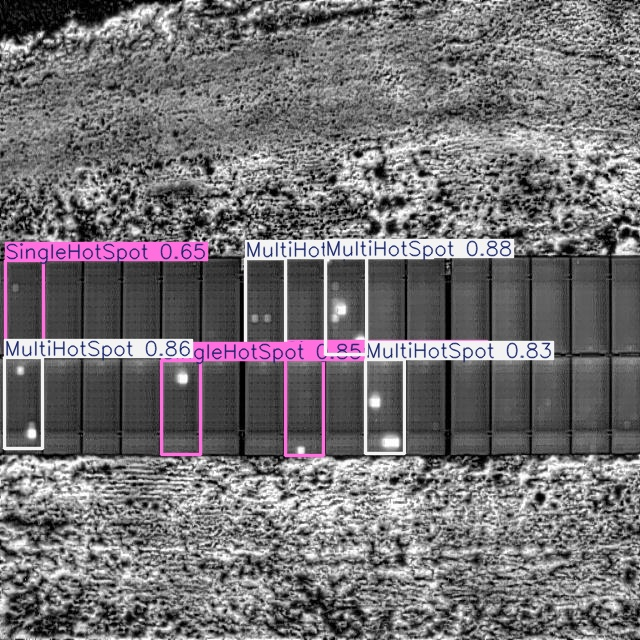


Image: 0raw_data_total_dataset_DJI_20230809115644_0005_T_jpg.rf.1c0b9bb11ffa0e689243de307e358260.jpg


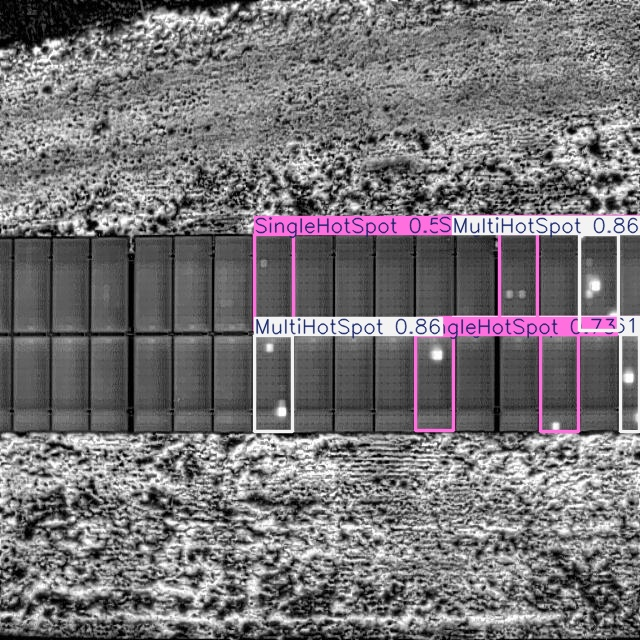


Image: 0raw_data_total_dataset_DJI_20230809115745_0013_T_jpg.rf.4574102c983c3e6621af9c806ee74b58.jpg


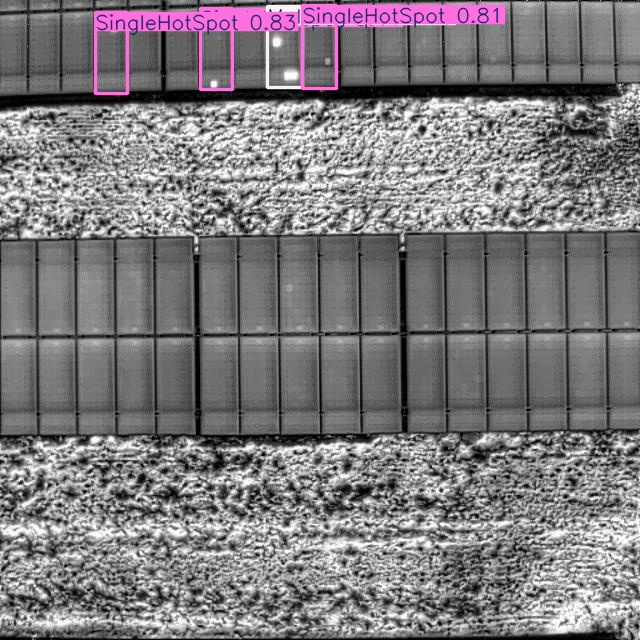

In [35]:
from pathlib import Path
from IPython.display import display, Image as DisplayImage

PRED_DIR = Path("/content/solar_dataset/predictions/validation")

predicted_images = sorted(
    p for p in PRED_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("Predicted images available:", len(predicted_images))

for path in predicted_images[:3]:
    print("\nImage:", path.name)
    display(DisplayImage(filename=str(path), width=600))

In [36]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd

# Paths
DATASET_DIR = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = DATASET_DIR / "valid" / "images"
LABEL_DIR = DATASET_DIR / "valid" / "labels"
PRED_DIR = Path("/content/solar_dataset/predictions/validation/labels")

CLASS_NAMES = [
    "MultiByPassed",
    "MultiDiode",
    "MultiHotSpot",
    "SingleByPassed",
    "SingleDiode",
    "SingleHotSpot",
    "StringOpenCircuit",
    "StringReversedPolarity"
]

IOU_THRESHOLD = 0.50

def read_yolo_boxes(path):
    boxes = []
    if not path.exists():
        return boxes

    for line in path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        cls, xc, yc, w, h = map(float, parts[:5])
        boxes.append((int(cls), xc, yc, w, h))

    return boxes

def box_iou(a, b):
    # YOLO-normalized center-format boxes -> corner coordinates
    ax1, ay1 = a[1] - a[3]/2, a[2] - a[4]/2
    ax2, ay2 = a[1] + a[3]/2, a[2] + a[4]/2

    bx1, by1 = b[1] - b[3]/2, b[2] - b[4]/2
    bx2, by2 = b[1] + b[3]/2, b[2] + b[4]/2

    iw = max(0, min(ax2, bx2) - max(ax1, bx1))
    ih = max(0, min(ay2, by2) - max(ay1, by1))
    intersection = iw * ih

    area_a = max(0, ax2-ax1) * max(0, ay2-ay1)
    area_b = max(0, bx2-bx1) * max(0, by2-by1)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# Per-class TP, FP, FN
counts = defaultdict(lambda: {"TP": 0, "FP": 0, "FN": 0})
images_evaluated = 0
missing_predictions = 0

for image_path in sorted(IMAGE_DIR.iterdir()):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp"}:
        continue

    gt_path = LABEL_DIR / f"{image_path.stem}.txt"
    pred_path = PRED_DIR / f"{image_path.stem}.txt"

    if not gt_path.exists():
        continue

    gt = read_yolo_boxes(gt_path)
    pred = read_yolo_boxes(pred_path)

    if not pred_path.exists():
        missing_predictions += 1

    images_evaluated += 1
    candidates = []

    # Match only detections of the same class
    for pi, p in enumerate(pred):
        for gi, g in enumerate(gt):
            if p[0] != g[0]:
                continue

            iou = box_iou(p, g)
            if iou >= IOU_THRESHOLD:
                candidates.append((iou, pi, gi, p[0]))

    candidates.sort(reverse=True)

    matched_pred = set()
    matched_gt = set()

    for iou, pi, gi, cls in candidates:
        if pi not in matched_pred and gi not in matched_gt:
            matched_pred.add(pi)
            matched_gt.add(gi)
            counts[cls]["TP"] += 1

    for pi, p in enumerate(pred):
        if pi not in matched_pred:
            counts[p[0]]["FP"] += 1

    for gi, g in enumerate(gt):
        if gi not in matched_gt:
            counts[g[0]]["FN"] += 1

rows = []

for cls_id, class_name in enumerate(CLASS_NAMES):
    tp = counts[cls_id]["TP"]
    fp = counts[cls_id]["FP"]
    fn = counts[cls_id]["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Class": class_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4)
    })

df = pd.DataFrame(rows)
display(df)

total_tp = df["TP"].sum()
total_fp = df["FP"].sum()
total_fn = df["FN"].sum()

p = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
r = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0
f1 = 2*p*r/(p+r) if p+r else 0

print("\nOVERALL CLASS-AWARE EVALUATION (IoU >= 0.50)")
print("Images evaluated:", images_evaluated)
print("Images without prediction label files:", missing_predictions)
print("TP:", total_tp, "| FP:", total_fp, "| FN:", total_fn)
print(f"Precision: {p:.4f}")
print(f"Recall:    {r:.4f}")
print(f"F1-score:  {f1:.4f}")

,Class,TP,FP,FN,Precision,Recall,F1
0,MultiByPassed,30,9,4,0.7692,0.8824,0.8219
1,MultiDiode,39,45,38,0.4643,0.5065,0.4845
2,MultiHotSpot,169,146,40,0.5365,0.8086,0.6450
3,SingleByPassed,241,70,22,0.7749,0.9163,0.8397
4,SingleDiode,90,49,38,0.6475,0.7031,0.6742
5,SingleHotSpot,255,119,68,0.6818,0.7895,0.7317
6,StringOpenCircuit,60,39,9,0.6061,0.8696,0.7143
7,StringReversedPolarity,9,2,7,0.8182,0.5625,0.6667



OVERALL CLASS-AWARE EVALUATION (IoU >= 0.50)
Images evaluated: 400
Images without prediction label files: 10
TP: 893 | FP: 479 | FN: 226
Precision: 0.6509
Recall:    0.7980
F1-score:  0.7170


In [37]:
from pathlib import Path

IMAGE_DIR = Path("/content/solar_dataset/yolo_ready/valid/images")
GT_DIR = Path("/content/solar_dataset/yolo_ready/valid/labels")
PRED_DIR = Path("/content/solar_dataset/predictions/validation/labels")

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

missing = []
empty_gt = []
empty_pred = []

for img in image_paths:
    gt = GT_DIR / f"{img.stem}.txt"
    pred = PRED_DIR / f"{img.stem}.txt"

    if not gt.exists():
        missing.append((img.name, "Missing ground-truth label"))
    elif not gt.read_text().strip():
        empty_gt.append(img.name)

    if not pred.exists():
        missing.append((img.name, "No prediction file"))
    elif not pred.read_text().strip():
        empty_pred.append(img.name)

print("Validation images:", len(image_paths))
print("Missing-file cases:", len(missing))
print("Empty ground-truth labels:", len(empty_gt))
print("Empty prediction files:", len(empty_pred))

print("\nFirst 15 missing-file cases:")
for item in missing[:15]:
    print(item)

Validation images: 400
Missing-file cases: 10
Empty ground-truth labels: 0
Empty prediction files: 0

First 15 missing-file cases:
('DJI_20220414140334_0332_T-JPG_jpg.rf.37c3feb30f67e2c7401654584a97a92f.jpg', 'No prediction file')
('DJI_20220606105850_0058_T_JPG_jpg.rf.a9913bcf67f8e101b525eac58c14f382.jpg', 'No prediction file')
('Infrared-Solar-Panel-Inspection_Infrared-Imaging-Services-LLC-2_jpg.rf.9f38f330c87af7383feb0bafd28b43b2.jpg', 'No prediction file')
('R14T4_jpg.rf.26e114c715c0545568c68a869b1cd8f6.jpg', 'No prediction file')
('Test_Solar_Image_008_JPG_jpg.rf.1875eaafd8f951a0d9e135f2c85a2c5c.jpg', 'No prediction file')
('imgFC727_png_jpg.rf.66d89dd8dabf2415ad41a554cdf42bc7.jpg', 'No prediction file')
('reverse-polarity-3_jpg.rf.975a13b8b49d13d0c16c1e1069a1178c.jpg', 'No prediction file')
('slkjhgf_jpg.rf.55275b5bcdb3c648f6085c2f90157a28.jpg', 'No prediction file')
('solar_color32_jpg.rf.dd945c5b4907bbd0ce0b8309e5427171.jpg', 'No prediction file')
('solar_color87_jpg.rf.18ef259

In [38]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Method": "Fixed threshold",
        "Configuration": "98th percentile; min area 500",
        "Precision": 0.0593,
        "Recall": 0.0708,
        "F1-score": 0.0645
    },
    {
        "Method": "Fixed threshold + morphological closing",
        "Configuration": "98th percentile; kernel 11; min area 200",
        "Precision": 0.0362,
        "Recall": 0.1504,
        "F1-score": 0.0584
    },
    {
        "Method": "Local intensity difference",
        "Configuration": "Threshold 20; min area 200",
        "Precision": 0.0042,
        "Recall": 0.0442,
        "F1-score": 0.0080
    },
    {
        "Method": "Local intensity difference + morphological closing",
        "Configuration": "Kernel 11; min area 200",
        "Precision": 0.0115,
        "Recall": 0.1239,
        "F1-score": 0.0210
    },
    {
        "Method": "YOLOv8n supervised detector",
        "Configuration": "Confidence 0.25; class-aware IoU >= 0.50",
        "Precision": 0.6509,
        "Recall": 0.7980,
        "F1-score": 0.7170
    }
])

display(
    comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

comparison.to_csv(
    "/content/solar_dataset/method_comparison_summary.csv",
    index=False
)

print("\nSaved to:")
print("/content/solar_dataset/method_comparison_summary.csv")

,Method,Configuration,Precision,Recall,F1-score
0,Fixed threshold,98th percentile; min area 500,0.0593,0.0708,0.0645
1,Fixed threshold + morphological closing,98th percentile; kernel 11; min area 200,0.0362,0.1504,0.0584
2,Local intensity difference,Threshold 20; min area 200,0.0042,0.0442,0.0080
3,Local intensity difference + morphological closing,Kernel 11; min area 200,0.0115,0.1239,0.0210
4,YOLOv8n supervised detector,Confidence 0.25; class-aware IoU >= 0.50,0.6509,0.7980,0.7170



Saved to:
/content/solar_dataset/method_comparison_summary.csv


In [39]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# Paths
ROOT = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = ROOT / "valid" / "images"
LABEL_DIR = ROOT / "valid" / "labels"

MODEL_PATH = (
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

# Evaluation settings
IOU_THRESHOLD = 0.50
MIN_AREA = 200
LOCAL_SIGMA = 9

model = YOLO(MODEL_PATH)

def load_gt_boxes(label_path, width, height):
    boxes = []

    if not label_path.exists():
        return boxes

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts[:5])

        x1 = max(0, int((xc - bw / 2) * width))
        y1 = max(0, int((yc - bh / 2) * height))
        x2 = min(width, int((xc + bw / 2) * width))
        y2 = min(height, int((yc + bh / 2) * height))

        if x2 > x1 and y2 > y1:
            boxes.append((int(cls), [x1, y1, x2, y2]))

    return boxes

def get_boxes_from_mask(mask, min_area=200):
    count, _, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    boxes = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area >= min_area:
            boxes.append([x, y, x + w, y + h])

    return boxes

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

def match_boxes(pred_boxes, gt_boxes, threshold=0.50):
    candidates = []

    for pi, pred in enumerate(pred_boxes):
        for gi, gt in enumerate(gt_boxes):
            iou = iou_xyxy(pred, gt)

            if iou >= threshold:
                candidates.append((iou, pi, gi))

    candidates.sort(reverse=True)

    matched_pred = set()
    matched_gt = set()

    for _, pi, gi in candidates:
        if pi not in matched_pred and gi not in matched_gt:
            matched_pred.add(pi)
            matched_gt.add(gi)

    tp = len(matched_pred)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn

def metric_row(name, tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "Method": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

totals = {
    "Fixed threshold": [0, 0, 0],
    "Neighborhood-normalized": [0, 0, 0],
    "YOLOv8n": [0, 0, 0]
}

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
)

print("Images to evaluate:", len(image_paths))

for index, path in enumerate(image_paths, 1):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        continue

    h, w = image.shape
    gt = load_gt_boxes(LABEL_DIR / f"{path.stem}.txt", w, h)
    gt_boxes = [box for _, box in gt]

    # 1. Fixed global threshold: 98th percentile
    smooth = cv2.GaussianBlur(
        image.astype(np.float32), (3, 3), 0
    )
    fixed_threshold = np.percentile(smooth, 98)
    fixed_mask = (smooth >= fixed_threshold).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (11, 11)
    )
    fixed_mask = cv2.morphologyEx(
        fixed_mask, cv2.MORPH_CLOSE, kernel
    )

    fixed_boxes = get_boxes_from_mask(fixed_mask, MIN_AREA)

    # 2. Neighborhood-normalized local z-score
    local_mean = cv2.GaussianBlur(
        smooth, (0, 0), sigmaX=LOCAL_SIGMA
    )
    local_sq_mean = cv2.GaussianBlur(
        smooth ** 2, (0, 0), sigmaX=LOCAL_SIGMA
    )
    local_std = np.sqrt(
        np.maximum(local_sq_mean - local_mean ** 2, 0)
    )
    z_score = (smooth - local_mean) / (local_std + 2.0)

    normalized_mask = (z_score >= 0.5).astype(np.uint8)
    normalized_mask = cv2.morphologyEx(
        normalized_mask, cv2.MORPH_CLOSE, kernel
    )

    normalized_boxes = get_boxes_from_mask(
        normalized_mask, MIN_AREA
    )

    # Evaluate the two class-agnostic baselines
    for name, pred_boxes in [
        ("Fixed threshold", fixed_boxes),
        ("Neighborhood-normalized", normalized_boxes)
    ]:
        tp, fp, fn = match_boxes(
            pred_boxes, gt_boxes, IOU_THRESHOLD
        )

        for j, value in enumerate([tp, fp, fn]):
            totals[name][j] += value

    # 3. YOLO detector, using the same image and GT boxes
    result = model.predict(
        source=str(path),
        conf=0.25,
        iou=0.5,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    yolo_boxes = []

    if result.boxes is not None and len(result.boxes):
        for xyxy in result.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = xyxy
            yolo_boxes.append([
                max(0, int(x1)),
                max(0, int(y1)),
                min(w, int(x2)),
                min(h, int(y2))
            ])

    tp, fp, fn = match_boxes(
        yolo_boxes, gt_boxes, IOU_THRESHOLD
    )

    for j, value in enumerate([tp, fp, fn]):
        totals["YOLOv8n"][j] += value

    if index % 50 == 0:
        print(f"Processed {index}/{len(image_paths)} images")

rows = []

for name, (tp, fp, fn) in totals.items():
    rows.append(metric_row(name, tp, fp, fn))

comparison = pd.DataFrame(rows)

print("\nCOMMON VALIDATION SET RESULTS")
display(
    comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

output_path = "/content/solar_dataset/common_validation_comparison.csv"
comparison.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Images to evaluate: 400
Processed 50/400 images
Processed 100/400 images
Processed 150/400 images
Processed 200/400 images
Processed 250/400 images
Processed 300/400 images
Processed 350/400 images
Processed 400/400 images

COMMON VALIDATION SET RESULTS


,Method,TP,FP,FN,Precision,Recall,F1-score
0,Fixed threshold,97,3704,1022,0.0255,0.0867,0.0394
1,Neighborhood-normalized,113,17845,1006,0.0063,0.1010,0.0118
2,YOLOv8n,977,395,142,0.7121,0.8731,0.7844



Saved: /content/solar_dataset/common_validation_comparison.csv


In [40]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = ROOT / "valid" / "images"
LABEL_DIR = ROOT / "valid" / "labels"

IOU_THRESHOLD = 0.50
MIN_AREA = 200
LOCAL_SIGMA = 9
CLOSING_KERNEL = 11

# Thresholds to compare
Z_THRESHOLDS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

def load_gt_boxes(label_path, width, height):
    boxes = []

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        _, xc, yc, bw, bh = map(float, parts[:5])

        x1 = max(0, int((xc - bw / 2) * width))
        y1 = max(0, int((yc - bh / 2) * height))
        x2 = min(width, int((xc + bw / 2) * width))
        y2 = min(height, int((yc + bh / 2) * height))

        if x2 > x1 and y2 > y1:
            boxes.append([x1, y1, x2, y2])

    return boxes


def get_boxes_from_mask(mask, min_area=200):
    count, _, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    boxes = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area >= min_area:
            boxes.append([x, y, x + w, y + h])

    return boxes


def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def evaluate_boxes(pred_boxes, gt_boxes, iou_threshold=0.50):
    candidates = []

    for pi, pred in enumerate(pred_boxes):
        for gi, gt in enumerate(gt_boxes):
            iou = calculate_iou(pred, gt)

            if iou >= iou_threshold:
                candidates.append((iou, pi, gi))

    candidates.sort(reverse=True)

    matched_pred = set()
    matched_gt = set()

    for _, pi, gi in candidates:
        if pi not in matched_pred and gi not in matched_gt:
            matched_pred.add(pi)
            matched_gt.add(gi)

    tp = len(matched_pred)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


def calculate_metrics(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1


image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
)

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (CLOSING_KERNEL, CLOSING_KERNEL)
)

totals = {
    threshold: [0, 0, 0]
    for threshold in Z_THRESHOLDS
}

for index, path in enumerate(image_paths, 1):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        continue

    h, w = image.shape

    gt_boxes = load_gt_boxes(
        LABEL_DIR / f"{path.stem}.txt", w, h
    )

    smooth = cv2.GaussianBlur(
        image.astype(np.float32), (3, 3), 0
    )

    local_mean = cv2.GaussianBlur(
        smooth, (0, 0), sigmaX=LOCAL_SIGMA
    )

    local_sq_mean = cv2.GaussianBlur(
        smooth ** 2, (0, 0), sigmaX=LOCAL_SIGMA
    )

    local_std = np.sqrt(
        np.maximum(local_sq_mean - local_mean ** 2, 0)
    )

    z_score = (smooth - local_mean) / (local_std + 2.0)

    for threshold in Z_THRESHOLDS:
        mask = (z_score >= threshold).astype(np.uint8)

        mask = cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel
        )

        pred_boxes = get_boxes_from_mask(mask, MIN_AREA)

        tp, fp, fn = evaluate_boxes(
            pred_boxes, gt_boxes, IOU_THRESHOLD
        )

        for j, value in enumerate([tp, fp, fn]):
            totals[threshold][j] += value

    if index % 100 == 0:
        print(f"Processed {index}/{len(image_paths)} images")

rows = []

for threshold, (tp, fp, fn) in totals.items():
    precision, recall, f1 = calculate_metrics(tp, fp, fn)

    rows.append({
        "Z_threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1
    })

results_df = pd.DataFrame(rows)

print("\nNEIGHBORHOOD-NORMALIZATION THRESHOLD COMPARISON")

display(
    results_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_score": "{:.4f}"
    })
)

output_path = "/content/solar_dataset/normalized_threshold_sweep.csv"
results_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Processed 100/400 images
Processed 200/400 images
Processed 300/400 images
Processed 400/400 images

NEIGHBORHOOD-NORMALIZATION THRESHOLD COMPARISON


,Z_threshold,TP,FP,FN,Precision,Recall,F1_score
0,0.500000,113,17845,1006,0.0063,0.1010,0.0118
1,1.000000,52,7669,1067,0.0067,0.0465,0.0118
2,1.500000,0,523,1119,0.0000,0.0000,0.0000
3,2.000000,1,57,1118,0.0172,0.0009,0.0017
4,2.500000,0,19,1119,0.0000,0.0000,0.0000
5,3.000000,0,10,1119,0.0000,0.0000,0.0000



Saved: /content/solar_dataset/normalized_threshold_sweep.csv


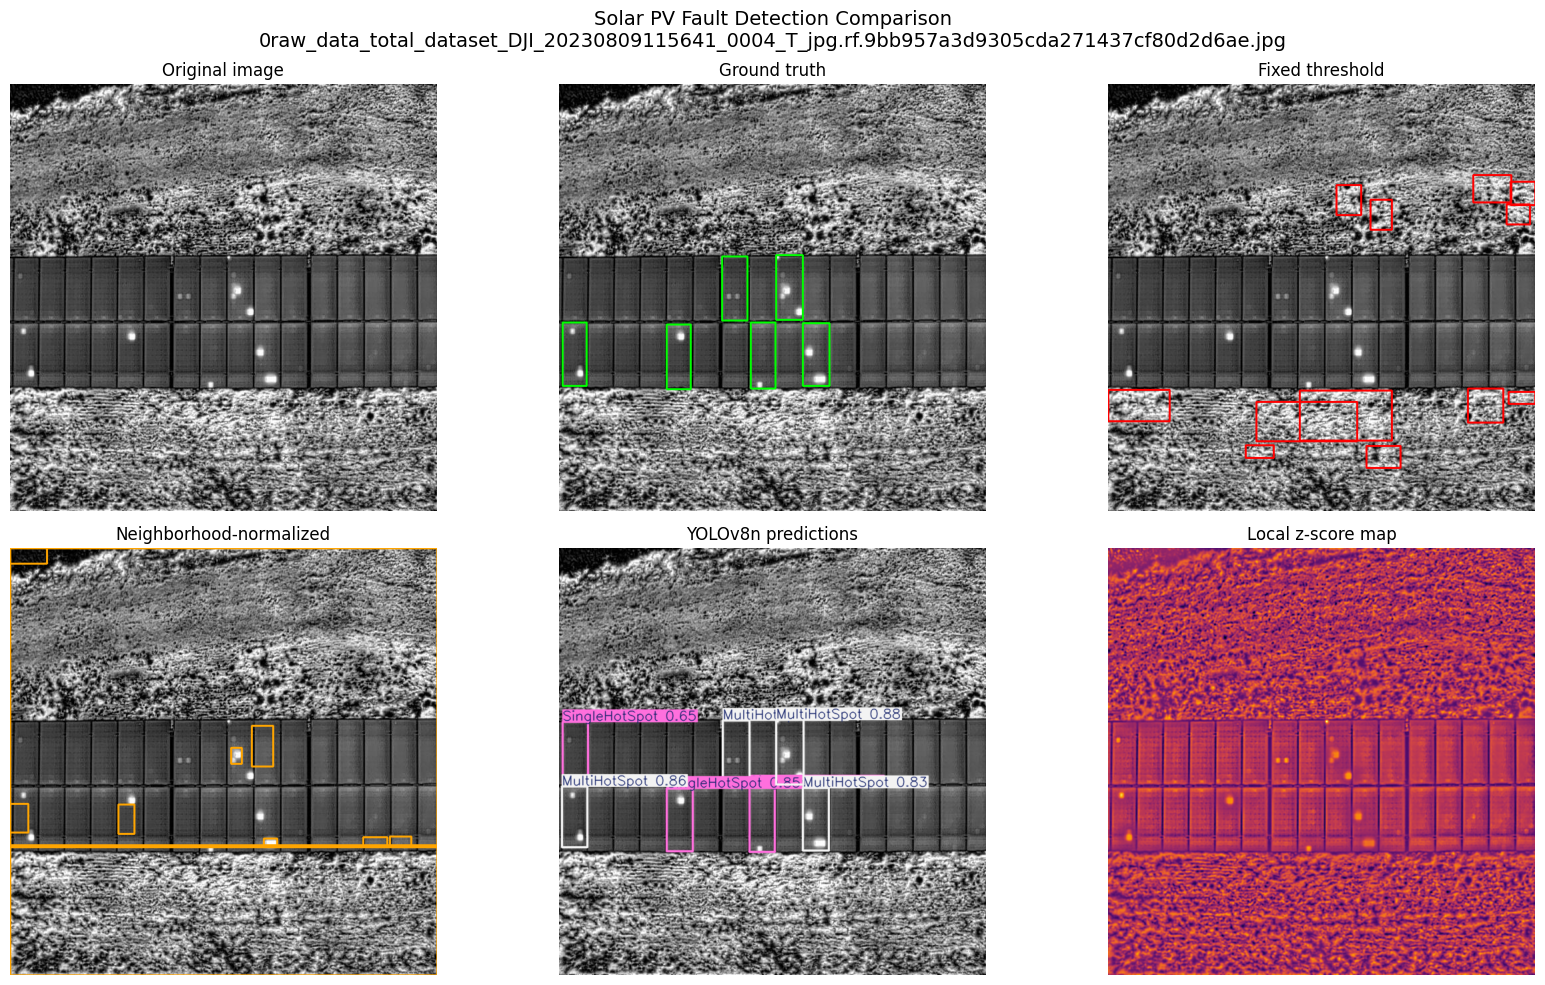

Image: 0raw_data_total_dataset_DJI_20230809115641_0004_T_jpg.rf.9bb957a3d9305cda271437cf80d2d6ae.jpg
Saved visualization: /content/solar_dataset/final_visualizations/validation_method_comparison.png


In [41]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

ROOT = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = ROOT / "valid" / "images"
LABEL_DIR = ROOT / "valid" / "labels"

MODEL_PATH = (
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

OUTPUT_DIR = Path("/content/solar_dataset/final_visualizations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(MODEL_PATH)

# Choose a validation image containing annotated faults.
image_path = None

for path in sorted(IMAGE_DIR.iterdir()):
    label_path = LABEL_DIR / f"{path.stem}.txt"

    if label_path.exists() and label_path.stat().st_size > 0:
        image_path = path
        break

if image_path is None:
    raise FileNotFoundError("No validation image with annotations found.")

gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if gray is None:
    raise ValueError(f"Could not read image: {image_path}")

h, w = gray.shape
rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

# Ground truth
ground_truth = rgb.copy()

with open(LABEL_DIR / f"{image_path.stem}.txt") as f:
    for line in f:
        parts = line.split()

        if len(parts) < 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts[:5])

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            ground_truth, (x1, y1), (x2, y2), (0, 255, 0), 2
        )

# Fixed threshold
smooth = cv2.GaussianBlur(gray.astype(np.float32), (3, 3), 0)
fixed_threshold = np.percentile(smooth, 98)
fixed_mask = (smooth >= fixed_threshold).astype(np.uint8)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
fixed_mask = cv2.morphologyEx(
    fixed_mask, cv2.MORPH_CLOSE, kernel
)

fixed_view = rgb.copy()

count, _, stats, _ = cv2.connectedComponentsWithStats(
    fixed_mask, connectivity=8
)

for i in range(1, count):
    x, y, bw, bh, area = stats[i]

    if area >= 200:
        cv2.rectangle(
            fixed_view, (x, y), (x + bw, y + bh), (255, 0, 0), 2
        )

# Neighborhood-normalized
local_mean = cv2.GaussianBlur(
    smooth, (0, 0), sigmaX=9, sigmaY=9
)

local_sq_mean = cv2.GaussianBlur(
    smooth ** 2, (0, 0), sigmaX=9, sigmaY=9
)

local_std = np.sqrt(
    np.maximum(local_sq_mean - local_mean ** 2, 0)
)

z_score = (smooth - local_mean) / (local_std + 2.0)
normalized_mask = (z_score >= 0.5).astype(np.uint8)

normalized_mask = cv2.morphologyEx(
    normalized_mask, cv2.MORPH_CLOSE, kernel
)

normalized_view = rgb.copy()

count, _, stats, _ = cv2.connectedComponentsWithStats(
    normalized_mask, connectivity=8
)

for i in range(1, count):
    x, y, bw, bh, area = stats[i]

    if area >= 200:
        cv2.rectangle(
            normalized_view,
            (x, y),
            (x + bw, y + bh),
            (255, 165, 0),
            2
        )

# YOLO predictions
prediction = model.predict(
    source=str(image_path),
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0,
    verbose=False
)[0]

yolo_view = prediction.plot()
yolo_view = cv2.cvtColor(yolo_view, cv2.COLOR_BGR2RGB)

# Display
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

panels = [
    ("Original image", rgb),
    ("Ground truth", ground_truth),
    ("Fixed threshold", fixed_view),
    ("Neighborhood-normalized", normalized_view),
    ("YOLOv8n predictions", yolo_view),
    ("Local z-score map", z_score)
]

for ax, (title, image) in zip(axes.flat, panels):
    if title == "Local z-score map":
        ax.imshow(image, cmap="inferno")
    else:
        ax.imshow(image)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Solar PV Fault Detection Comparison\n{image_path.name}",
    fontsize=14
)
plt.tight_layout()

figure_path = OUTPUT_DIR / "validation_method_comparison.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Image:", image_path.name)
print("Saved visualization:", figure_path)

In [42]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

ROOT = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = ROOT / "test" / "images"
LABEL_DIR = ROOT / "test" / "labels"

MODEL_PATH = (
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

IOU_THRESHOLD = 0.50
MIN_AREA = 200
LOCAL_SIGMA = 9
CLOSING_KERNEL = 11

model = YOLO(MODEL_PATH)

def load_gt_boxes(label_path, width, height):
    boxes = []

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        _, xc, yc, bw, bh = map(float, parts[:5])

        x1 = max(0, int((xc - bw / 2) * width))
        y1 = max(0, int((yc - bh / 2) * height))
        x2 = min(width, int((xc + bw / 2) * width))
        y2 = min(height, int((yc + bh / 2) * height))

        if x2 > x1 and y2 > y1:
            boxes.append([x1, y1, x2, y2])

    return boxes


def get_boxes_from_mask(mask):
    count, _, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    boxes = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area >= MIN_AREA:
            boxes.append([x, y, x + w, y + h])

    return boxes


def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def evaluate_boxes(pred_boxes, gt_boxes):
    candidates = []

    for pi, pred in enumerate(pred_boxes):
        for gi, gt in enumerate(gt_boxes):
            iou = calculate_iou(pred, gt)

            if iou >= IOU_THRESHOLD:
                candidates.append((iou, pi, gi))

    candidates.sort(reverse=True)

    matched_pred = set()
    matched_gt = set()

    for _, pi, gi in candidates:
        if pi not in matched_pred and gi not in matched_gt:
            matched_pred.add(pi)
            matched_gt.add(gi)

    tp = len(matched_pred)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


def calculate_metrics(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1


image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
)

print("Test images:", len(image_paths))

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (CLOSING_KERNEL, CLOSING_KERNEL)
)

totals = {
    "Fixed threshold": [0, 0, 0],
    "Neighborhood-normalized": [0, 0, 0],
    "YOLOv8n": [0, 0, 0]
}

for index, path in enumerate(image_paths, 1):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("WARNING: Could not read", path.name)
        continue

    h, w = image.shape
    gt_boxes = load_gt_boxes(
        LABEL_DIR / f"{path.stem}.txt", w, h
    )

    # 1. Fixed global threshold
    smooth = cv2.GaussianBlur(
        image.astype(np.float32), (3, 3), 0
    )

    threshold = np.percentile(smooth, 98)
    fixed_mask = (smooth >= threshold).astype(np.uint8)

    fixed_mask = cv2.morphologyEx(
        fixed_mask, cv2.MORPH_CLOSE, kernel
    )

    fixed_boxes = get_boxes_from_mask(fixed_mask)

    # 2. Neighborhood-normalized z-score
    local_mean = cv2.GaussianBlur(
        smooth, (0, 0), sigmaX=LOCAL_SIGMA
    )

    local_sq_mean = cv2.GaussianBlur(
        smooth ** 2, (0, 0), sigmaX=LOCAL_SIGMA
    )

    local_std = np.sqrt(
        np.maximum(local_sq_mean - local_mean ** 2, 0)
    )

    z_score = (smooth - local_mean) / (local_std + 2.0)
    normalized_mask = (z_score >= 0.5).astype(np.uint8)

    normalized_mask = cv2.morphologyEx(
        normalized_mask, cv2.MORPH_CLOSE, kernel
    )

    normalized_boxes = get_boxes_from_mask(normalized_mask)

    # 3. YOLOv8n
    result = model.predict(
        source=str(path),
        conf=0.25,
        iou=0.5,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    yolo_boxes = []

    if result.boxes is not None and len(result.boxes):
        for box in result.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = box

            yolo_boxes.append([
                max(0, int(x1)),
                max(0, int(y1)),
                min(w, int(x2)),
                min(h, int(y2))
            ])

    # Same class-agnostic box matching for all methods
    for name, predictions in [
        ("Fixed threshold", fixed_boxes),
        ("Neighborhood-normalized", normalized_boxes),
        ("YOLOv8n", yolo_boxes)
    ]:
        tp, fp, fn = evaluate_boxes(predictions, gt_boxes)

        for j, value in enumerate([tp, fp, fn]):
            totals[name][j] += value

    print(f"Processed {index}/{len(image_paths)}: {path.name}")

rows = []

for name, (tp, fp, fn) in totals.items():
    precision, recall, f1 = calculate_metrics(tp, fp, fn)

    rows.append({
        "Method": name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1
    })

test_results = pd.DataFrame(rows)

print("\nFINAL TEST SET RESULTS")
display(test_results.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1_score": "{:.4f}"
}))

output_path = "/content/solar_dataset/final_test_results.csv"
test_results.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Ground-truth objects:", sum(totals[m][0] + totals[m][2] for m in totals))

Test images: 15
Processed 1/15: 0raw_data_total_dataset_DJI_20230809115646_0006_T_jpg.rf.c0b14af525fab877a150a44ee6bfc1f3.jpg
Processed 2/15: 101MEDIA_DJI_0333_T_JPG_jpg.rf.13d79587843a1f42dac0797208e8eee8.jpg
Processed 3/15: 101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d149112f7a62c294c6d300.jpg
Processed 4/15: 101MEDIA_DJI_0361_T_JPG_jpg.rf.c8e41676aa3376d7f77ff631b9216600.jpg
Processed 5/15: 101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e60aa3a5996bd96627.jpg
Processed 6/15: 101MEDIA_DJI_0421_T_JPG_jpg.rf.f51996aa55703f0b77cd6643c1e29606.jpg
Processed 7/15: 101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19d653bb222add4a164.jpg
Processed 8/15: 101MEDIA_DJI_0477_T_JPG_jpg.rf.e6e020dd4efe1db8461cc749dba7327f.jpg
Processed 9/15: 124_jpg.rf.a50e9cd85618126df170f30070e282b7.jpg
Processed 10/15: 210_jpg.rf.babdcab5fd00a84a15bb7d95b2d649d5.jpg
Processed 11/15: 318_jpg.rf.a52a0fd9e3729f7cd0b3b1afcfeea914.jpg
Processed 12/15: 335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg
Processed 13/15: 338_jpg.rf

,Method,TP,FP,FN,Precision,Recall,F1_score
0,Fixed threshold,1,130,30,0.0076,0.0323,0.0123
1,Neighborhood-normalized,3,830,28,0.0036,0.0968,0.0069
2,YOLOv8n,31,18,0,0.6327,1.0000,0.7750



Saved: /content/solar_dataset/final_test_results.csv
Ground-truth objects: 93


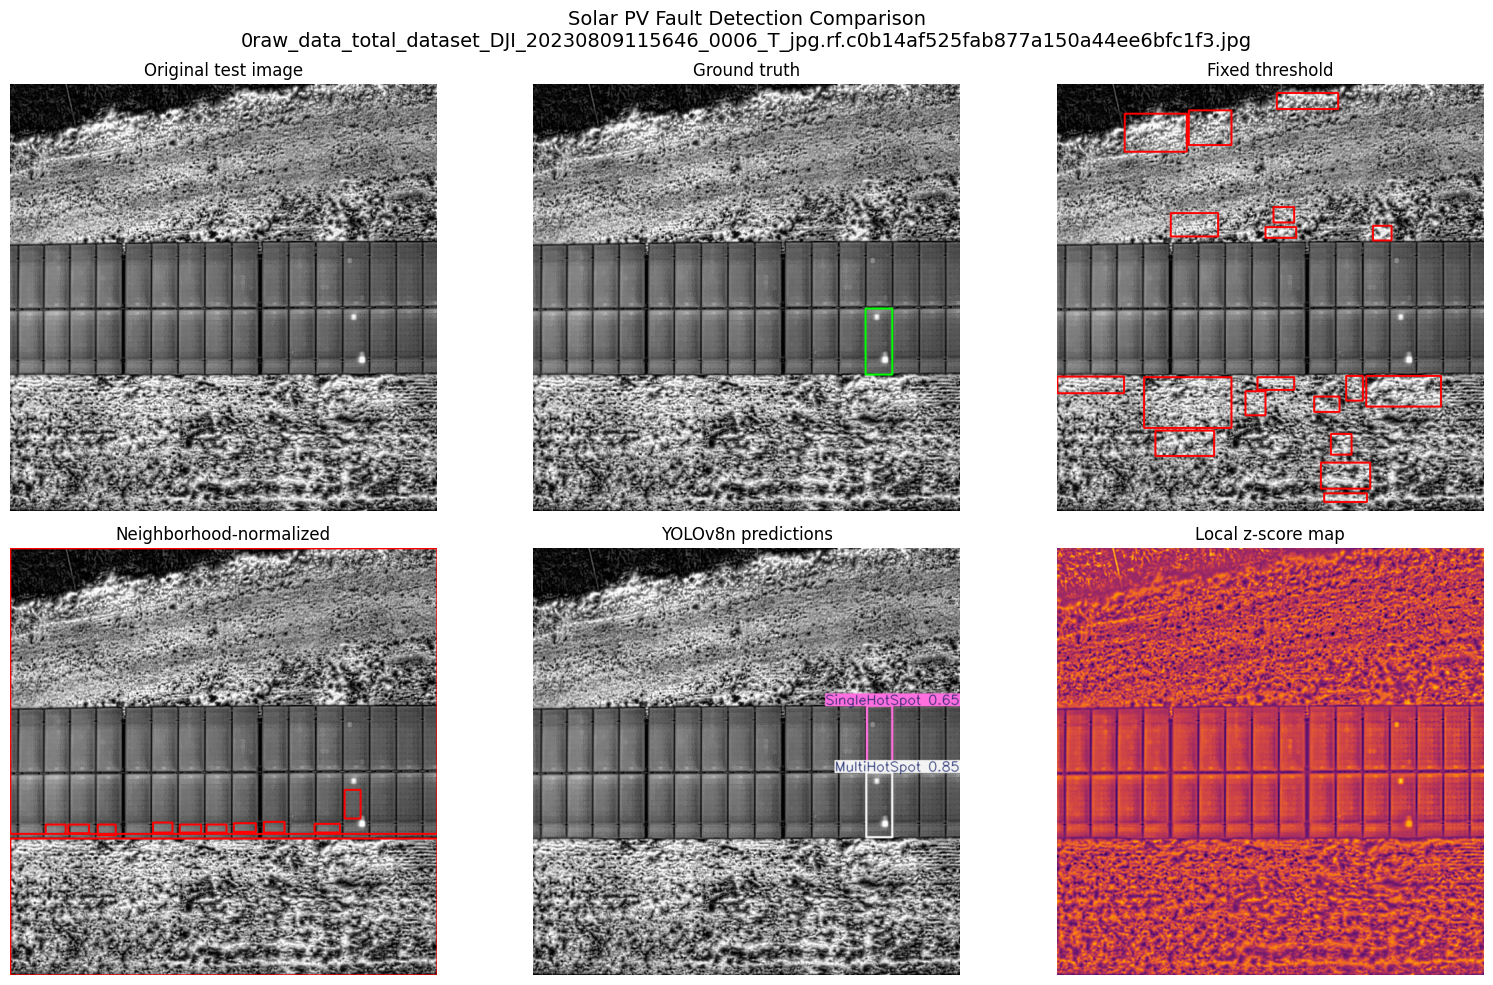

Selected image: 0raw_data_total_dataset_DJI_20230809115646_0006_T_jpg.rf.c0b14af525fab877a150a44ee6bfc1f3.jpg
Saved figure: /content/solar_dataset/final_visualizations/final_test_comparison.png


In [43]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

ROOT = Path("/content/solar_dataset/yolo_ready")
IMAGE_DIR = ROOT / "test" / "images"
LABEL_DIR = ROOT / "test" / "labels"

MODEL_PATH = (
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

OUTPUT_DIR = Path("/content/solar_dataset/final_visualizations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(MODEL_PATH)

# Select the first test image containing ground-truth annotations.
image_path = next(
    p for p in sorted(IMAGE_DIR.iterdir())
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    and (LABEL_DIR / f"{p.stem}.txt").exists()
    and (LABEL_DIR / f"{p.stem}.txt").stat().st_size > 0
)

gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if gray is None:
    raise ValueError(f"Cannot read {image_path}")

h, w = gray.shape
rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

# Ground truth
gt_view = rgb.copy()

with open(LABEL_DIR / f"{image_path.stem}.txt") as f:
    for line in f:
        parts = line.split()
        if len(parts) < 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts[:5])

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            gt_view, (x1, y1), (x2, y2), (0, 255, 0), 2
        )

# Shared settings for the handcrafted methods
smooth = cv2.GaussianBlur(
    gray.astype(np.float32), (3, 3), 0
)

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (11, 11)
)

def draw_component_boxes(mask, min_area=200):
    view = rgb.copy()

    count, _, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    for i in range(1, count):
        x, y, bw, bh, area = stats[i]

        if area >= min_area:
            cv2.rectangle(
                view, (x, y), (x + bw, y + bh), (255, 0, 0), 2
            )

    return view

# Fixed threshold
fixed_threshold = np.percentile(smooth, 98)
fixed_mask = (smooth >= fixed_threshold).astype(np.uint8)

fixed_mask = cv2.morphologyEx(
    fixed_mask, cv2.MORPH_CLOSE, kernel
)

fixed_view = draw_component_boxes(fixed_mask)

# Neighborhood normalization
local_mean = cv2.GaussianBlur(
    smooth, (0, 0), sigmaX=9, sigmaY=9
)

local_sq_mean = cv2.GaussianBlur(
    smooth ** 2, (0, 0), sigmaX=9, sigmaY=9
)

local_std = np.sqrt(
    np.maximum(local_sq_mean - local_mean ** 2, 0)
)

z_score = (smooth - local_mean) / (local_std + 2.0)
normalized_mask = (z_score >= 0.5).astype(np.uint8)

normalized_mask = cv2.morphologyEx(
    normalized_mask, cv2.MORPH_CLOSE, kernel
)

normalized_view = draw_component_boxes(normalized_mask)

# YOLOv8n predictions
prediction = model.predict(
    source=str(image_path),
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0,
    verbose=False
)[0]

yolo_view = cv2.cvtColor(
    prediction.plot(), cv2.COLOR_BGR2RGB
)

# Display and save
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

panels = [
    ("Original test image", rgb),
    ("Ground truth", gt_view),
    ("Fixed threshold", fixed_view),
    ("Neighborhood-normalized", normalized_view),
    ("YOLOv8n predictions", yolo_view),
    ("Local z-score map", z_score)
]

for ax, (title, panel) in zip(axes.flat, panels):
    if title == "Local z-score map":
        ax.imshow(panel, cmap="inferno")
    else:
        ax.imshow(panel)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Solar PV Fault Detection Comparison\n{image_path.name}",
    fontsize=14
)
plt.tight_layout()

save_path = OUTPUT_DIR / "final_test_comparison.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected image:", image_path.name)
print("Saved figure:", save_path)

#Severity Score

In [51]:
import os
from pathlib import Path

base = Path("/content/solar_dataset")

model_path = (
    base / "training_runs" /
    "yolov8n_solar_faults" / "weights" / "best.pt"
)

test_images = base / "yolo_ready" / "test" / "images"

print("=== MODEL ===")
print("Trained YOLO model exists:", model_path.exists())

print("\n=== TEST DATA ===")
print("Test image folder exists:", test_images.exists())

if test_images.exists():
    images = [
        p for p in test_images.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]
    print("Test images found:", len(images))

print("\n=== LLM SETUP ===")
print("Gemini API key available:", bool(os.environ.get("GEMINI_API_KEY")))

try:
    import google.generativeai
    print("Google Generative AI package: available")
except ImportError:
    print("Google Generative AI package: not installed")

=== MODEL ===
Trained YOLO model exists: True

=== TEST DATA ===
Test image folder exists: True
Test images found: 15

=== LLM SETUP ===
Gemini API key available: False
Google Generative AI package: not installed


In [75]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import cv2

# Paths
base = Path("/content/solar_dataset")
model_path = (
    base / "training_runs" /
    "yolov8n_solar_faults" / "weights" / "best.pt"
)
test_dir = base / "yolo_ready" / "test" / "images"

# Class names
CLASS_NAMES = [
    "MultiByPassed",
    "MultiDiode",
    "MultiHotSpot",
    "SingleByPassed",
    "SingleDiode",
    "SingleHotSpot",
    "StringOpenCircuit",
    "StringReversedPolarity"
]

# Load trained model
model = YOLO(str(model_path))

# Get test images
image_paths = sorted([
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

records = []

for image_path in image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]
    image_area = height * width

    # Run YOLO inference
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        # Keep coordinates within image boundaries
        x1 = max(0, min(x1, width - 1))
        x2 = max(x1 + 1, min(x2, width))
        y1 = max(0, min(y1, height - 1))
        y2 = max(y1 + 1, min(y2, height))

        # Bounding-box area relative to full image
        box_area = (x2 - x1) * (y2 - y1)
        area_percent = 100 * box_area / image_area

        # Approximate local intensity contrast
        # Compare the box with a surrounding ring.
        pad = max(5, int(min(width, height) * 0.02))

        rx1 = max(0, x1 - pad)
        ry1 = max(0, y1 - pad)
        rx2 = min(width, x2 + pad)
        ry2 = min(height, y2 + pad)

        surrounding = gray[ry1:ry2, rx1:rx2].copy()

        # Exclude the detected box from the surrounding region
        mx1, my1 = x1 - rx1, y1 - ry1
        mx2, my2 = x2 - rx1, y2 - ry1
        surrounding[my1:my2, mx1:mx2] = 0

        ring_mask = cv2.dilate(
            cv2.rectangle(
                cv2.UMat(
                    __import__("numpy").zeros(
                        (height, width), dtype="uint8"
                    )
                ),
                (x1, y1), (x2 - 1, y2 - 1), 255, -1
            ).get(),
            cv2.getStructuringElement(
                cv2.MORPH_RECT, (2 * pad + 1, 2 * pad + 1)
            )
        )

        # Use the local surrounding region, excluding the box
        ring = gray[ry1:ry2, rx1:rx2]
        local_mask = __import__("numpy").ones(
            ring.shape, dtype=bool
        )
        local_mask[my1:my2, mx1:mx2] = False

        if local_mask.any():
            local_mean = float(ring[local_mask].mean())
        else:
            local_mean = float(gray.mean())

        box_mean = float(gray[y1:y2, x1:x2].mean())
        contrast = box_mean - local_mean

        records.append({
            "image": image_path.name,
            "fault_class": CLASS_NAMES[class_id],
            "confidence": round(confidence, 4),
            "area_percent": round(area_percent, 4),
            "box_mean_intensity": round(box_mean, 2),
            "local_mean_intensity": round(local_mean, 2),
            "local_contrast": round(contrast, 2),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

# Save detection features
output_path = base / "severity_detection_features.csv"
df = pd.DataFrame(records)
df.to_csv(output_path, index=False)

print("Test images:", len(image_paths))
print("Fault detections:", len(df))
print("Saved to:", output_path)

if not df.empty:
    display(df.head(10))
else:
    print("No detections at confidence 0.25. Check the model or confidence threshold.")

Test images: 15
Fault detections: 49
Saved to: /content/solar_dataset/severity_detection_features.csv


,image,fault_class,confidence,area_percent,box_mean_intensity,local_mean_intensity,local_contrast,x1,y1,x2,y2
0,0raw_data_total_dataset_DJI_20230809115646_000...,MultiHotSpot,0.8504,0.9236,99.70,90.95,8.75,499,336,538,433
1,0raw_data_total_dataset_DJI_20230809115646_000...,SingleHotSpot,0.6516,0.8999,89.90,88.66,1.24,500,236,538,333
2,101MEDIA_DJI_0333_T_JPG_jpg.rf.13d79587843a1f4...,MultiHotSpot,0.6196,1.9226,130.35,120.94,9.41,122,552,227,627
3,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.8432,2.8975,142.06,129.38,12.68,12,133,55,409
4,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.8094,2.9004,102.67,92.97,9.70,581,134,625,404
5,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.5237,3.0659,143.32,129.77,13.55,57,132,96,454
6,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.4090,0.9297,103.55,122.02,-18.47,626,128,640,400
7,101MEDIA_DJI_0361_T_JPG_jpg.rf.c8e41676aa3376d...,MultiHotSpot,0.8289,1.3403,97.32,88.37,8.95,255,15,300,137
8,101MEDIA_DJI_0361_T_JPG_jpg.rf.c8e41676aa3376d...,MultiHotSpot,0.7891,1.3105,80.70,70.00,10.70,7,138,51,260
9,101MEDIA_DJI_0361_T_JPG_jpg.rf.c8e41676aa3376d...,MultiHotSpot,0.7055,1.4487,97.13,72.59,24.54,53,393,99,522


In [53]:
import pandas as pd
import numpy as np
from pathlib import Path

base = Path("/content/solar_dataset")
input_path = base / "severity_detection_features.csv"

df = pd.read_csv(input_path)

# Normalize local contrast to a 0–100 visual indicator.
# Positive contrast indicates a brighter region than its surroundings.
df["contrast_score"] = (
    df["local_contrast"].clip(lower=0, upper=40) / 40 * 100
)

# Normalize relative bounding-box area.
# 5% of the image is used as a scaling reference, not an engineering threshold.
df["area_score"] = (
    df["area_percent"].clip(lower=0, upper=5) / 5 * 100
)

# Model confidence is included as supporting information only.
df["confidence_score"] = df["confidence"].clip(0, 1) * 100

# Heuristic visual priority score.
# Contrast receives the highest weight; area and confidence receive lower weights.
df["severity_score"] = (
    0.60 * df["contrast_score"]
    + 0.20 * df["area_score"]
    + 0.20 * df["confidence_score"]
).round(2)

# Provisional categories for organizing inspection examples.
# These are not validated physical severity thresholds.
df["severity_category"] = pd.cut(
    df["severity_score"],
    bins=[-0.01, 33.33, 66.67, 100],
    labels=["Low", "Medium", "High"]
).astype(str)

# Save results
output_path = base / "severity_scored_detections.csv"
df.to_csv(output_path, index=False)

print("Total detections scored:", len(df))
print("Saved to:", output_path)

print("\nSeverity category counts:")
print(df["severity_category"].value_counts())

print("\nTop 10 detections by estimated severity score:")
display(
    df.sort_values("severity_score", ascending=False)[
        [
            "image",
            "fault_class",
            "confidence",
            "local_contrast",
            "area_percent",
            "severity_score",
            "severity_category"
        ]
    ].head(10)
)

Total detections scored: 49
Saved to: /content/solar_dataset/severity_scored_detections.csv

Severity category counts:
severity_category
Medium    24
High      14
Low       11
Name: count, dtype: int64

Top 10 detections by estimated severity score:


,image,fault_class,confidence,local_contrast,area_percent,severity_score,severity_category
10,101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e...,SingleByPassed,0.9002,42.48,1.4824,83.93,High
19,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,SingleDiode,0.7914,41.38,1.4150,81.49,High
22,101MEDIA_DJI_0477_T_JPG_jpg.rf.e6e020dd4efe1db...,MultiHotSpot,0.7727,45.73,1.2715,80.54,High
37,335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg,SingleDiode,0.9231,51.04,0.2832,79.59,High
23,124_jpg.rf.a50e9cd85618126df170f30070e282b7.jpg,MultiHotSpot,0.7939,50.67,0.6714,78.56,High
18,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,SingleDiode,0.8098,37.40,1.5146,78.35,High
38,335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg,SingleDiode,0.7916,55.36,0.3125,77.08,High
20,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,MultiHotSpot,0.5220,43.48,1.5586,76.67,High
21,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,MultiDiode,0.4892,41.60,1.5911,76.15,High
30,210_jpg.rf.babdcab5fd00a84a15bb7d95b2d649d5.jpg,MultiHotSpot,0.7166,48.91,0.3076,75.56,High


In [77]:
import pandas as pd

csv_path = "/content/solar_dataset/severity_scored_detections.csv"
df = pd.read_csv(csv_path)

# Select representative detections from each severity category
selected = (
    df.sort_values("severity_score", ascending=False)
      .groupby("severity_category", group_keys=False)
      .head(4)
)

# Arrange categories in a meaningful order
category_order = {"High": 0, "Medium": 1, "Low": 2}
selected["category_order"] = selected["severity_category"].map(category_order)

selected = selected.sort_values(
    ["category_order", "severity_score"],
    ascending=[True, False]
)

columns = [
    "image",
    "fault_class",
    "confidence",
    "local_contrast",
    "area_percent",
    "severity_score",
    "severity_category"
]

print("Representative detections across severity categories:")
display(selected[columns].round(3).reset_index(drop=True))

print("\nCategory counts in the selected table:")
print(selected["severity_category"].value_counts())

Representative detections across severity categories:


,image,fault_class,confidence,local_contrast,area_percent,severity_score,severity_category
0,101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e...,SingleByPassed,0.900,42.48,1.482,83.93,High
1,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,SingleDiode,0.791,41.38,1.415,81.49,High
2,101MEDIA_DJI_0477_T_JPG_jpg.rf.e6e020dd4efe1db...,MultiHotSpot,0.773,45.73,1.272,80.54,High
3,335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg,SingleDiode,0.923,51.04,0.283,79.59,High
4,101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e...,SingleByPassed,0.788,26.72,1.624,62.33,Medium
5,34_jpg.rf.8b04ac700de15154bf791ab1b5da9425.jpg,SingleHotSpot,0.582,30.38,1.010,61.25,Medium
6,124_jpg.rf.a50e9cd85618126df170f30070e282b7.jpg,MultiHotSpot,0.400,32.34,0.686,59.25,Medium
7,124_jpg.rf.a50e9cd85618126df170f30070e282b7.jpg,MultiHotSpot,0.760,27.19,0.585,58.32,Medium
8,7_jpg.rf.ba676cc70d9046f852287dd7b9cbfdf5.jpg,SingleByPassed,0.788,9.90,0.596,32.99,Low
9,101MEDIA_DJI_0421_T_JPG_jpg.rf.f51996aa55703f0...,MultiHotSpot,0.795,5.64,1.193,29.13,Low



Category counts in the selected table:
severity_category
High      4
Medium    4
Low       4
Name: count, dtype: int64


In [58]:
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

print("Gemini API key loaded:", bool(api_key))

Gemini API key loaded: True


In [60]:
from google import genai
print("Gemini SDK imported successfully!")

Gemini SDK imported successfully!


In [61]:
from google.colab import userdata
from google import genai

api_key = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

print("Gemini client initialized successfully!")

Gemini client initialized successfully!


In [62]:
from google import genai
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

print("Checking available Gemini models...\n")

for model in client.models.list():
    name = model.name
    if "gemini" in name.lower():
        print(name)

Checking available Gemini models...

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/g

In [63]:
import pandas as pd
import os

# Load existing severity-scored detections
csv_path = "/content/solar_dataset/severity_scored_detections.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Could not find {csv_path}. "
        "Check that your previous severity-scoring cell ran successfully."
    )

df = pd.read_csv(csv_path)

print("CSV loaded successfully!")
print("Total detections:", len(df))
print("Unique test images:", df["image"].nunique())

print("\nSeverity distribution:")
print(df["severity_category"].value_counts())

print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())

CSV loaded successfully!
Total detections: 49
Unique test images: 15

Severity distribution:
severity_category
Medium    24
High      14
Low       11
Name: count, dtype: int64

Available columns:
['image', 'fault_class', 'confidence', 'area_percent', 'box_mean_intensity', 'local_mean_intensity', 'local_contrast', 'x1', 'y1', 'x2', 'y2', 'contrast_score', 'area_score', 'confidence_score', 'severity_score', 'severity_category']


,image,fault_class,confidence,area_percent,box_mean_intensity,local_mean_intensity,local_contrast,x1,y1,x2,y2,contrast_score,area_score,confidence_score,severity_score,severity_category
0,0raw_data_total_dataset_DJI_20230809115646_000...,MultiHotSpot,0.8504,0.9236,99.70,90.95,8.75,499,336,538,433,21.875,18.472,85.04,33.83,Medium
1,0raw_data_total_dataset_DJI_20230809115646_000...,SingleHotSpot,0.6516,0.8999,89.90,88.66,1.24,500,236,538,333,3.100,17.998,65.16,18.49,Low
2,101MEDIA_DJI_0333_T_JPG_jpg.rf.13d79587843a1f4...,MultiHotSpot,0.6196,1.9226,130.35,120.94,9.41,122,552,227,627,23.525,38.452,61.96,34.20,Medium
3,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.8432,2.8975,142.06,129.38,12.68,12,133,55,409,31.700,57.950,84.32,47.47,Medium
4,101MEDIA_DJI_0343_T_JPG_jpg.rf.ea0ecc6614d1491...,SingleByPassed,0.8094,2.9004,102.67,92.97,9.70,581,134,625,404,24.250,58.008,80.94,42.34,Medium


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


# Automatic Inspection Report Generation

In [64]:
import json
from collections import Counter

# Summarize the existing severity-scored detections
severity_counts = df["severity_category"].value_counts().to_dict()
fault_counts = df["fault_class"].value_counts().to_dict()

# Select the highest-priority detections for the report
top_detections = (
    df.sort_values("severity_score", ascending=False)
      .head(10)[
          [
              "image",
              "fault_class",
              "confidence",
              "area_percent",
              "local_contrast",
              "severity_score",
              "severity_category"
          ]
      ]
      .round(3)
      .to_dict(orient="records")
)

inspection_data = {
    "project": "Neighbourhood-Normalized Thermal Anomaly Detection for UAV-Based Solar Photovoltaic Inspection",
    "test_images": int(df["image"].nunique()),
    "total_detections": int(len(df)),
    "severity_distribution": severity_counts,
    "fault_class_distribution": fault_counts,
    "top_10_detections": top_detections,
    "severity_score_note": (
        "The severity score is a heuristic visual-priority score calculated "
        "from local contrast, detected area percentage, and model confidence. "
        "It is not a calibrated physical severity measurement."
    )
}

print(json.dumps(inspection_data, indent=2))

{
  "project": "Neighbourhood-Normalized Thermal Anomaly Detection for UAV-Based Solar Photovoltaic Inspection",
  "test_images": 15,
  "total_detections": 49,
  "severity_distribution": {
    "Medium": 24,
    "High": 14,
    "Low": 11
  },
  "fault_class_distribution": {
    "MultiHotSpot": 17,
    "SingleByPassed": 13,
    "SingleDiode": 11,
    "SingleHotSpot": 6,
    "MultiDiode": 1,
    "StringOpenCircuit": 1
  },
  "top_10_detections": [
    {
      "image": "101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e60aa3a5996bd96627.jpg",
      "fault_class": "SingleByPassed",
      "confidence": 0.9,
      "area_percent": 1.482,
      "local_contrast": 42.48,
      "severity_score": 83.93,
      "severity_category": "High"
    },
    {
      "image": "101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19d653bb222add4a164.jpg",
      "fault_class": "SingleDiode",
      "confidence": 0.791,
      "area_percent": 1.415,
      "local_contrast": 41.38,
      "severity_score": 81.49,
      "severity_c

In [68]:
%pip install -q groq

In [70]:
from google.colab import userdata
from groq import Groq

client = Groq(api_key=userdata.get("GROQ_API_KEY"))

models = client.models.list()

print("Available models:\n")

for model in models.data:
    if not getattr(model, "active", True):
        continue
    print(model.id)

Available models:

openai/gpt-oss-120b
canopylabs/orpheus-arabic-saudi
whisper-large-v3
meta-llama/llama-prompt-guard-2-22m
allam-2-7b
openai/gpt-oss-20b
canopylabs/orpheus-v1-english
whisper-large-v3-turbo
qwen/qwen3.8-27b
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-safeguard-20b


In [71]:
from google.colab import userdata
from groq import Groq

client = Groq(api_key=userdata.get("GROQ_API_KEY"))

response = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: LLM connection successful."
        }
    ],
    max_tokens=50
)

print(response.choices[0].message.content)

LLM connection successful.


In [72]:
import json
from pathlib import Path
from google.colab import userdata
from groq import Groq

# Connect to Groq
client = Groq(api_key=userdata.get("GROQ_API_KEY"))

# Check that the existing project data is available
print("Project:", inspection_data["project"])
print("Test images:", inspection_data["test_images"])
print("Total detections:", inspection_data["total_detections"])

# Prepare the report-generation prompt
report_prompt = f"""
You are an AI assistant helping prepare a solar photovoltaic inspection report.

PROJECT DATA:
{json.dumps(inspection_data, indent=2, default=str)}

TASK:
Generate a clear, professional technical inspection report with these sections:

1. Executive Summary
2. Detection Statistics
3. Fault-Class Analysis
4. High-Priority Findings
5. Recommended Inspection Actions
6. Limitations and Future Improvements

RULES:
- Use only the supplied project data.
- Report exactly 15 test images and the supplied detection counts.
- Explain that the severity score is a heuristic visual-priority score,
  not a validated physical severity measurement.
- Model confidence is not physical severity.
- Do not invent temperatures, power losses, root causes, or maintenance outcomes.
- Present recommendations as suggestions for human inspection.
- Clearly state that the test set is small and results are preliminary.
- Do not claim that the method is fully validated.
- Use concise technical language suitable for an academic project report.
"""

# Generate report
response = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
        {
            "role": "system",
            "content": "You are a careful technical writer specializing in AI-assisted solar PV inspection."
        },
        {
            "role": "user",
            "content": report_prompt
        }
    ],
    temperature=0.3,
    max_tokens=2500
)

report = response.choices[0].message.content

# Save the report
output_path = Path("/content/solar_dataset/llm_inspection_report.md")
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(report, encoding="utf-8")

print("\nREPORT GENERATED SUCCESSFULLY\n")
print(report)
print(f"\nSaved to: {output_path}")

Project: Neighbourhood-Normalized Thermal Anomaly Detection for UAV-Based Solar Photovoltaic Inspection
Test images: 15
Total detections: 49

REPORT GENERATED SUCCESSFULLY

**Neighbourhood‑Normalized Thermal Anomaly Detection for UAV‑Based Solar Photovoltaic Inspection**  
*Inspection Report – Test Set of 15 UAV‑captured images*  

---

### 1. Executive Summary  
The UAV‑based thermal imaging system was evaluated on a limited test set of 15 images, yielding 49 anomaly detections. The detections span six fault classes and are distributed across three severity categories (High, Medium, Low). The most frequently identified faults are Multi‑HotSpot (17), Single‑ByPassed (13), and Single‑Diode (11). The top‑10 detections are all classified as High severity, with confidence values ranging from 0.49 to 0.92 and area percentages between 0.28 % and 1.59 %.  

The severity score, derived from local contrast, detected area, and model confidence, is a heuristic visual‑priority metric and **not** a

In [73]:
import pandas as pd

csv_path = "/content/solar_dataset/severity_scored_detections.csv"
df = pd.read_csv(csv_path)

print("Total detections:", len(df))
print("\nSeverity distribution:")
print(df["severity_category"].value_counts())

print("\nFault-class distribution:")
print(df["fault_class"].value_counts())

print("\nTop 10 detections:")
cols = [
    "image", "fault_class", "confidence", "area_percent",
    "local_contrast", "severity_score", "severity_category"
]
display(df.nlargest(10, "severity_score")[cols].round(3))

Total detections: 49

Severity distribution:
severity_category
Medium    24
High      14
Low       11
Name: count, dtype: int64

Fault-class distribution:
fault_class
MultiHotSpot         17
SingleByPassed       13
SingleDiode          11
SingleHotSpot         6
MultiDiode            1
StringOpenCircuit     1
Name: count, dtype: int64

Top 10 detections:


,image,fault_class,confidence,area_percent,local_contrast,severity_score,severity_category
10,101MEDIA_DJI_0385_T_JPG_jpg.rf.a4741f39b710b1e...,SingleByPassed,0.900,1.482,42.48,83.93,High
19,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,SingleDiode,0.791,1.415,41.38,81.49,High
22,101MEDIA_DJI_0477_T_JPG_jpg.rf.e6e020dd4efe1db...,MultiHotSpot,0.773,1.272,45.73,80.54,High
37,335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg,SingleDiode,0.923,0.283,51.04,79.59,High
23,124_jpg.rf.a50e9cd85618126df170f30070e282b7.jpg,MultiHotSpot,0.794,0.671,50.67,78.56,High
18,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,SingleDiode,0.810,1.515,37.40,78.35,High
38,335_jpg.rf.c86c171d5fd2718151e1d424b021f650.jpg,SingleDiode,0.792,0.312,55.36,77.08,High
20,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,MultiHotSpot,0.522,1.559,43.48,76.67,High
21,101MEDIA_DJI_0435_T_JPG_jpg.rf.156a9022cef8a19...,MultiDiode,0.489,1.591,41.60,76.15,High
30,210_jpg.rf.babdcab5fd00a84a15bb7d95b2d649d5.jpg,MultiHotSpot,0.717,0.308,48.91,75.56,High


In [74]:
from pathlib import Path

model_path = Path(
    "/content/solar_dataset/training_runs/"
    "yolov8n_solar_faults/weights/best.pt"
)

test_images_dir = Path(
    "/content/solar_dataset/yolo_ready/test/images"
)

report_path = Path(
    "/content/solar_dataset/llm_inspection_report.md"
)

print("YOLO model exists:", model_path.exists())
print("Test image folder exists:", test_images_dir.exists())
print("LLM report exists:", report_path.exists())

if test_images_dir.exists():
    images = list(test_images_dir.glob("*"))
    images = [p for p in images if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
    print("Number of test images:", len(images))

if report_path.exists():
    print("Report size:", report_path.stat().st_size, "bytes")

YOLO model exists: True
Test image folder exists: True
LLM report exists: True
Number of test images: 15
Report size: 6351 bytes
